# Studio Proyek 3: Fine-Tuning Transformer Pretrained untuk Klasifikasi Sentimen Bahasa Indonesia (SmSA)

Mata kuliah: Pembelajaran Mendalam

Dataset: SmSA dari IndoNLU

| NO | NAMA | NIM |
|---|---|---|
| 1 | Silvia | 123140133 |
| 2 | Tri putri Sormin | 123140013 |



In [ ]:
# 0. PEMERIKSAAN LINGKUNGAN

import sys, os, gc, json, time, math, random, hashlib, platform, subprocess, warnings, importlib, contextlib
warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"


def pastikan(paket, nama_pip=None):
    """Pasang paket hanya kalau belum ada (Colab/Kaggle sudah menyediakan sebagian besar)."""
    if importlib.util.find_spec(paket) is None:
        print(f"  memasang {paket} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", nama_pip or paket], check=False)


for _p in ["numpy", "pandas", "torch", "transformers", "sklearn", "matplotlib", "tqdm"]:
    pastikan(_p)

import numpy as np
import pandas as pd
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix

GPU = torch.cuda.is_available()
DEVICE = torch.device("cuda" if GPU else "cpu")

print("Python        :", platform.python_version())
print("torch         :", torch.__version__)
print("transformers  :", __import__("transformers").__version__)
print("perangkat     :", DEVICE, ("- " + torch.cuda.get_device_name(0)) if GPU else "(TANPA GPU: uji cepat saja)")
if GPU:
    print("VRAM          : %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))
else:
    print("\nCATATAN: tanpa GPU pelatihan sangat lambat. Pakai SUBSET_TRAIN kecil hanya untuk menguji alur.")

Python        : 3.13.16
torch         : 2.14.1+cu130
transformers  : 5.22.1
perangkat     : cuda - Tesla T4
VRAM          : 15.6 GB


In [ ]:
# 1. KONFIGURASI
DATASET_NAME = "smsa"
MEMBER_TAG = "anggota1"

BACKBONES = {
    "mBERT":      "bert-base-multilingual-cased",
    "DistilBERT": "distilbert-base-multilingual-cased",
    "IndoBERT":   "indobenchmark/indobert-base-p1",
    "XLM-R":      "xlm-roberta-base",
}
STRATEGIES = ["full", "partial", "probing"]
SEEDS      = [42, 123, 2026]

N_TRAIN           = 6000   # data latih 3.000-6.000 sampel
STRATIFIKASI_SEED = 42
N_VALID           = None
BASELINE_TFIDF    = True

MAX_LENGTH   = 128
BATCH_SIZE   = 32
EVAL_BATCH   = 64
EPOCHS       = 3
LR_BY_STRATEGY = {"full": 2e-5, "partial": 2e-5, "probing": 1e-3}
WARMUP_RATIO = 0.10
WEIGHT_DECAY = 0.01
GRAD_CLIP    = 1.0
LABELS       = ["positive", "neutral", "negative"]
LABEL2ID     = {l: i for i, l in enumerate(LABELS)}


RUN_BACKBONES  = list(BACKBONES)
RUN_STRATEGIES = list(STRATEGIES)
RUN_SEEDS      = list(SEEDS)
RESUME             = True
STRICT_DETERMINISM = True
USE_AMP            = False
LATENCY_N          = 200
SUBSET_TRAIN       = None
SUBSET_EVAL        = None

# kode konfigurasi
_SIG = {
    "dataset": DATASET_NAME, "backbones": BACKBONES, "strategies": STRATEGIES, "seeds": SEEDS,
    "max_length": MAX_LENGTH, "batch_size": BATCH_SIZE, "epochs": EPOCHS,
    "subset_train": SUBSET_TRAIN, "subset_eval": SUBSET_EVAL, "n_train": N_TRAIN, "stratifikasi_seed": STRATIFIKASI_SEED, "n_valid": N_VALID,
    "lr_by_strategy": LR_BY_STRATEGY, "warmup_ratio": WARMUP_RATIO,
    "weight_decay": WEIGHT_DECAY, "grad_clip": GRAD_CLIP, "labels": LABELS,
}
KODE = hashlib.md5(json.dumps(_SIG, sort_keys=True).encode()).hexdigest()[:8]

HASIL_ANGGOTA_CSV = f"hasil_{DATASET_NAME}_{KODE}_{MEMBER_TAG}.csv"
HASIL_CSV         = f"hasil_{DATASET_NAME}_{KODE}.csv"
AGREGAT_CSV       = f"rekap_agregat_{DATASET_NAME}_{KODE}.csv"

JUMLAH_RUN = len(RUN_BACKBONES) * len(RUN_STRATEGIES) * len(RUN_SEEDS)
print(f"Kode konfigurasi      : {KODE}")
print(f"Matriks penuh         : {len(BACKBONES)} backbone x {len(STRATEGIES)} strategi x {len(SEEDS)} seed "
      f"= {len(BACKBONES) * len(STRATEGIES) * len(SEEDS)} run")
print(f"Giliran notebook ini  : {JUMLAH_RUN} run ({MEMBER_TAG})")
print(f"Subset data           : latih {N_TRAIN} (stratified, seed {STRATIFIKASI_SEED}) | "
      f"validasi {'seluruh split resmi' if N_VALID is None else N_VALID} | uji 500 (uji resmi penuh)")
print(f"Berkas hasil (anggota): {HASIL_ANGGOTA_CSV}")
print(f"Berkas hasil (kanonik): {HASIL_CSV} , {AGREGAT_CSV}")

Kode konfigurasi      : c7e6d734
Matriks penuh         : 4 backbone x 3 strategi x 3 seed = 36 run
Giliran notebook ini  : 36 run (anggota1)
Subset data           : latih 6000 (stratified, seed 42) | validasi seluruh split resmi | uji 500 (uji resmi penuh)
Berkas hasil (anggota): hasil_smsa_c7e6d734_anggota1.csv
Berkas hasil (kanonik): hasil_smsa_c7e6d734.csv , rekap_agregat_smsa_c7e6d734.csv


In [ ]:
# 2. SEL RANCANGAN

RANCANGAN = """
=== SOAL 1: RANCANGAN EKSPERIMEN ===

Tujuan: membandingkan pengaruh backbone pretrained dan strategi fine-tuning terhadap akurasi
dan efisiensi klasifikasi sentimen Bahasa Indonesia (SmSA, 3 kelas: positive/neutral/negative).

--- HIPOTESIS ---
H1 (kecocokan bahasa): dengan protokol identik, F1-makro validasi mengikuti urutan
   IndoBERT-base-p1 > mBERT > DistilBERT-multilingual, karena prapelatihan monolingual
   Indonesia memberi representasi yang lebih dekat dengan domain SmSA, sedangkan DistilBERT
   kapasitasnya paling kecil. H1 ditolak bila mBERT/DistilBERT menyamai atau mengalahkan
   IndoBERT secara konsisten di ketiga seed.

H2 (strategi): F1-makro mengikuti urutan full >= partial freezing > linear probing, tetapi
   partial freezing memberi rasio F1 terhadap waktu latih terbaik, karena membekukan
   embedding + separuh lapis awal memangkas komputasi gradien dengan penurunan F1 yang kecil.
   H2 ditolak bila probing menyaingi full, atau partial justru mengalahkan full.

H3 (hasil menurun pada penambahan parameter): XLM-R (278 juta parameter) tidak memberi kenaikan
   F1-makro sepadan -- selisihnya terhadap mBERT diperkirakan kurang dari 1 poin F1 -- sementara
   waktu latih dan latensi inferensinya jelas lebih tinggi. H3 ditolak bila XLM-R menang
   lebih dari 1 poin F1 secara konsisten.

--- VARIABEL TERKENDALI (dikunci sebelum eksperimen) ---
dataset = SmSA (Opsi A yang DISARANKAN lembar studi kasus), memakai pembagian resmi.
   Data LATIH: 6.000 sampel diambil dari 10.933 baris bersih secara STRATIFIED per kelas dengan seed 42.
   Alasan: ketentuan lembar studi kasus mewajibkan data latih 3.000-6.000 sampel agar seluruh run selesai
   dalam waktu studio; 6.000 dipilih di batas atas agar akurasi maksimal, dan stratified dipakai supaya
   proporsi kelas minoritas (neutral) tidak tergeser. Untuk uji cepat boleh diturunkan, tapi angka final
   semua anggota WAJIB memakai 6.000 agar setara.
   Data VALIDASI: seluruh split resmi (1.246 baris setelah pembersihan) - dipakai HANYA untuk memilih epoch
   terbaik dan memilih konfigurasi, sesuai ketentuan.
   Data UJI: seluruh uji resmi SmSA (500 kalimat), disentuh sekali saja di akhir setiap run.
max_length = 128 token. Alasan berbasis pengukuran: pada 128 hanya 0,03-0,17% contoh terpotong,
   sedangkan pada 64 terpotong 18,3-30,9% (kalimat SmSA rata-rata 33 kata, maksimum 110 kata).
padding = dinamis (pad ke panjang terpanjang dalam batch), karena panjang token p50 hanya 33-44.
batch size = 32 untuk pelatihan, 64 untuk evaluasi.
epoch = 3 untuk semua run, agar anggaran langkah setiap kombinasi setara.
seed acak = 42, 123, 2026 (3 seed, sama untuk semua run).
learning rate = full 2e-5, partial 2e-5, probing 1e-3. Full dan partial sengaja disamakan supaya
   satu-satunya pembeda keduanya adalah himpunan parameter yang dilatih.
optimizer = AdamW, weight decay 0,01 (tanpa bias/LayerNorm), jadwal warmup linear 10%, grad clip 1,0.
determinisme = set_seed() + cudnn deterministic + generator urutan shuffle per run.

--- VARIABEL BEBAS ---
backbone (4): mBERT, DistilBERT-multilingual, IndoBERT-base-p1, XLM-R-base
strategi (3): full fine-tuning, partial freezing, linear probing
seed (3): 42, 123, 2026
Total: 4 x 3 x 3 = 36 run.

--- MATRIKS EKSPERIMEN ---
Setiap sel = satu backbone x satu strategi x satu seed. Protokol identik di semua sel; yang
berubah hanya backbone, strategi, dan seed. Jumlah parameter yang dilatih:
  mBERT      full 177.855.747 | partial 43.120.131 | probing 2.307
  DistilBERT full 135.326.979 | partial 21.856.515 | probing 592.899
  IndoBERT   full 124.443.651 | partial 43.120.131 | probing 2.307
  XLM-R      full 278.045.955 | partial 43.120.131 | probing 592.899
Urutan probing < partial < full diperiksa otomatis oleh notebook sebelum pelatihan.

--- PEMBERSIHAN DATA (SmSA, pembagian resmi) ---
1. buang baris kosong / label tak dikenal
2. buang teks berlabel bertentangan (teks sama, label berbeda)
3. buang duplikat teks pada data latih (simpan kemunculan pertama)
4. buang teks validasi yang juga muncul di data latih (mencegah kebocoran data)
5. lakukan hal yang sama pada data test
Hasil pemeriksaan pada berkas resmi: 67 duplikat di train, 14 baris validasi bocor ke train,
0 teks berlabel bertentangan.

--- METRIK DAN ATURAN PELAPORAN ---
Per run: akurasi dan F1-makro validasi, F1 tiap kelas, akurasi & F1-makro test, waktu latih,
latensi inferensi (ms/kalimat), jumlah parameter total dan yang dilatih, memori GPU puncak.
Pelaporan: rata-rata +- simpangan baku antar-seed (bukan run terbaik). Pemilihan konfigurasi
terbaik memakai split VALIDASI saja; data test dilaporkan sekali di akhir. Latensi hanya
dibandingkan antar-run dalam sesi/perangkat yang sama.

--- RENCANA ANALISIS ---
1. tabel agregat F1-makro per backbone x strategi beserta simpangan bakunya
2. memeriksa H1, H2, H3 terhadap hasil
3. grafik: F1-makro per sel (error bar), latensi vs F1 (ukuran titik = jumlah parameter),
   dan total vs parameter dilatih
4. analisis kesalahan pada konfigurasi terbaik: confusion matrix + contoh salah klasifikasi
5. rekomendasi akhir menimbang akurasi, anggaran komputasi, dan kecepatan inferensi

--- PEMBANDING YANG SAH ---
Lembar studi kasus menegaskan tidak ada angka "yang benar". Pembanding yang dipakai:
(a) baseline TF-IDF + regresi logistik yang dilatih pada data latih yang SAMA (data latih penuh pada versi
    lembar studi kasus memberi F1-makro sekitar 0,73 - angka itu milik mereka, bukan hasil kami),
(b) tebakan acak (1/3 = 0,33 untuk 3 kelas), dan
(c) simpangan baku antar-seed kami sendiri.
Pola yang diharapkan lembar studi kasus: full fine-tuning tertinggi atau setara, partial freezing sedikit di
bawah atau setara, linear probing umumnya terendah. Selisih yang lebih kecil dari simpangan antar-seed
dinyatakan BELUM berbeda. F1-makro di atas 0,97 patut dicurigai kebocoran data, dan di bawah baseline TF-IDF
biasanya berarti learning rate tidak sesuai, label salah dipetakan, atau model belum terlatih.

--- TIGA PERTANYAAN RISET WAJIB ---
Q1. Backbone mana yang memberi trade-off akurasi-vs-efisiensi terbaik untuk klasifikasi sentimen ini?
    Jawaban harus menyebut F1-makro +- simpangan baku, waktu latih, waktu inferensi, dan jumlah parameter.
Q2. Apakah strategi hemat komputasi (probing/partial) cukup kompetitif dibanding full fine-tuning?
    Bandingkan selisih skor dengan simpangan antar-seed, lalu tentukan apakah selisihnya bermakna.
Q3. Kombinasi apa yang akan direkomendasikan, dan mengapa? Tetapkan kriteria lebih dulu, lalu kaitkan
    dengan anggaran komputasi, kecepatan inferensi yang terukur, dan keterjelasan.
Rencana menjawab: notebook menyediakan sel khusus yang menghitung bahan ketiga jawaban dari CSV hasil.
"""


MIN_KARAKTER_RANCANGAN = 800
UNSUR_WAJIB = ["H1", "H2", "H3", "max_length", "batch size", "epoch", "seed"]
_isi = RANCANGAN.strip()
_hilang = [u for u in UNSUR_WAJIB if u.lower() not in _isi.lower()]
if len(_isi) < MIN_KARAKTER_RANCANGAN:
    raise RuntimeError(
        f"Sel Rancangan terlalu pendek ({len(_isi)} karakter, minimal {MIN_KARAKTER_RANCANGAN}). "
        "Isi dulu hipotesis, matriks eksperimen, dan variabel terkendali sebelum menjalankan eksperimen."
    )
if _hilang:
    raise RuntimeError(f"Sel Rancangan belum memuat unsur wajib: {_hilang}. Lengkapi dulu sebelum eksperimen.")

print(f"Rancangan OK ({len(_isi)} karakter). Semua unsur wajib ada: {UNSUR_WAJIB}\n")

_matrik = pd.DataFrame(
    [{"backbone": bb, "model_id": BACKBONES[bb], "strategi": st, "seed": sd,
      "dijalankan_anggota_ini": (bb in RUN_BACKBONES and st in RUN_STRATEGIES and sd in RUN_SEEDS)}
     for bb in BACKBONES for st in STRATEGIES for sd in SEEDS]
)
print(f"Rancangan matriks: {len(_matrik)} sel ({_matrik['backbone'].nunique()} backbone x "
      f"{_matrik['strategi'].nunique()} strategi x {_matrik['seed'].nunique()} seed)")
_matrik

Rancangan OK (6705 karakter). Semua unsur wajib ada: ['H1', 'H2', 'H3', 'max_length', 'batch size', 'epoch', 'seed']

Rancangan matriks: 36 sel (4 backbone x 3 strategi x 3 seed)


,backbone,model_id,strategi,seed,dijalankan_anggota_ini
0,mBERT,bert-base-multilingual-cased,full,42,True
1,mBERT,bert-base-multilingual-cased,full,123,True
2,mBERT,bert-base-multilingual-cased,full,2026,True
3,mBERT,bert-base-multilingual-cased,partial,42,True
4,mBERT,bert-base-multilingual-cased,partial,123,True
5,mBERT,bert-base-multilingual-cased,partial,2026,True
6,mBERT,bert-base-multilingual-cased,probing,42,True
7,mBERT,bert-base-multilingual-cased,probing,123,True
8,mBERT,bert-base-multilingual-cased,probing,2026,True
9,DistilBERT,distilbert-base-multilingual-cased,full,42,True


## 3. Unduh dan baca data SmSA

Sumber resminya repositori IndoNLP/indonlu di folder dataset/smsa_doc-sentiment-prosa. Berkasnya berbentuk TSV tanpa header. Kolom pertama berisi teks dan kolom kedua berisi label. Urutan label mengikuti konstanta resmi dataset yaitu positive 0, neutral 1, dan negative 2.

Notebook ini tidak memakai library datasets karena spesifikasi hanya mewajibkannya untuk IMDb. Data dibaca langsung dengan pandas sehingga tidak terganggu perubahan versi datasets yang sudah tidak mendukung skrip pemuatan lama IndoNLU.


In [ ]:
# 3a. UNDUH / TEMUKAN BERKAS DATA

import urllib.request

DATA_DIR = "data_smsa"
os.makedirs(DATA_DIR, exist_ok=True)
FILES = {"train": "train_preprocess.tsv", "valid": "valid_preprocess.tsv", "test": "test_preprocess.tsv"}
BASE_URL = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/"


def cari_berkas_lokal(nama):
    for kandidat in [os.path.join(DATA_DIR, nama), nama, os.path.join("/content", nama),
                     os.path.join("/kaggle/input", nama), os.path.join("/kaggle/working", nama)]:
        if os.path.exists(kandidat) and os.path.getsize(kandidat) > 0:
            return kandidat
    return None


def siapkan_berkas(nama):
    lokal = cari_berkas_lokal(nama)
    if lokal:
        print(f"  {nama}: memakai berkas lokal {lokal}")
        return lokal
    tujuan = os.path.join(DATA_DIR, nama)
    url = BASE_URL + nama
    try:
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=60) as r, open(tujuan, "wb") as f:
            f.write(r.read())
        print(f"  {nama}: terunduh ({os.path.getsize(tujuan) / 1e6:.2f} MB)")
        return tujuan
    except Exception as e:
        raise RuntimeError(
            f"Gagal mengunduh {url}\n({type(e).__name__}: {e})\n\n"
            "Solusi: unduh manual tiga berkas TSV berikut, unggah ke folder notebook ini, lalu jalankan ulang sel:\n"
            f"  {BASE_URL}train_preprocess.tsv\n"
            f"  {BASE_URL}valid_preprocess.tsv\n"
            f"  {BASE_URL}test_preprocess.tsv"
        )


print("Menyiapkan berkas data SmSA:")
BERKAS = {k: siapkan_berkas(v) for k, v in FILES.items()}

Menyiapkan berkas data SmSA:
  train_preprocess.tsv: terunduh (2.19 MB)
  valid_preprocess.tsv: terunduh (0.25 MB)
  test_preprocess.tsv: terunduh (0.08 MB)


In [ ]:
# 3b. BACA BERKAS (dengan pemeriksa urutan kolom)

def baca_split(path, nama):
    """Baca TSV SmSA. Kolom label dideteksi otomatis supaya tidak salah kalau urutannya tertukar."""
    mentah = pd.read_csv(path, sep="\t", header=None, dtype=str, keep_default_na=False, na_filter=False)
    mentah = mentah.dropna(axis=1, how="all")
    if mentah.shape[1] < 2:
        raise ValueError(f"{nama}: berkas hanya punya {mentah.shape[1]} kolom, seharusnya 2 (teks, label).")
    if not (set(mentah.iloc[0].tolist()) & set(LABELS)):      # buang baris header bila ada
        mentah = mentah.iloc[1:].reset_index(drop=True)
    frac = [mentah[c].isin(LABELS).mean() for c in mentah.columns[:2]]
    kol_label = 0 if frac[0] >= frac[1] else 1
    kol_teks = 1 - kol_label
    df = pd.DataFrame({"text": mentah[kol_teks].astype(str).str.strip(),
                       "label": mentah[kol_label].astype(str).str.strip()})
    tak_dikenal = sorted(set(df["label"]) - set(LABELS))
    if tak_dikenal:
        raise ValueError(f"{nama}: ada label di luar daftar resmi: {tak_dikenal}")
    print(f"  {nama}: {len(df):,} baris | kolom label = kolom ke-{kol_label + 1}")
    return df


TRAIN = baca_split(BERKAS["train"], "train")
VALID = baca_split(BERKAS["valid"], "valid")
TEST = baca_split(BERKAS["test"], "test")

LABEL_TEST_TERSEDIA = (TEST["label"].nunique() > 1)
if not LABEL_TEST_TERSEDIA:
    print("\nCATATAN: label data test tampak tertutup (masked). Metrik test akan dilewati; "
          "metrik utama dilaporkan dari split validasi.")

print("\nDistribusi kelas (sebelum pembersihan):")
_dist = pd.DataFrame({n: d["label"].value_counts().reindex(LABELS) for n, d in
                      [("train", TRAIN), ("valid", VALID), ("test", TEST)]})
_dist.loc["TOTAL"] = _dist.sum()
print(_dist.to_string())
_rasio = _dist.loc[LABELS, "train"].max() / max(1, _dist.loc[LABELS, "train"].min())
print(f"\nRasio kelas mayoritas : minoritas pada data latih = {_rasio:.1f} : 1 "
      f"-> metrik utama F1-makro (bukan akurasi saja).")

  train: 11,000 baris | kolom label = kolom ke-2
  valid: 1,260 baris | kolom label = kolom ke-2
  test: 500 baris | kolom label = kolom ke-2

Distribusi kelas (sebelum pembersihan):
          train  valid  test
label                       
positive   6416    735   208
neutral    1148    131    88
negative   3436    394   204
TOTAL     11000   1260   500

Rasio kelas mayoritas : minoritas pada data latih = 5.6 : 1 -> metrik utama F1-makro (bukan akurasi saja).


In [ ]:
# ============================================================
# 4. PEMBERSIHAN DATA (lima langkah sesuai spesifikasi)
# ============================================================
def kunci_teks(s):
    return s.astype(str).str.strip().str.lower()


CATATAN_BERSIH = []


def catat(langkah, sebelum, sesudah, keterangan=""):
    CATATAN_BERSIH.append({"langkah": langkah, "sebelum": sebelum, "sesudah": sesudah,
                           "dibuang": sebelum - sesudah, "keterangan": keterangan})


def buang_bertentangan(df, nama):
    """Buang semua baris yang teksnya sama tetapi labelnya berbeda."""
    kerja = df.assign(_k=kunci_teks(df["text"]))
    ragam = kerja.groupby("_k")["label"].nunique()
    konflik = set(ragam[ragam > 1].index)
    sebelum = len(kerja)
    hasil = kerja[~kerja["_k"].isin(konflik)].drop(columns="_k").reset_index(drop=True)
    catat(f"{nama}: buang teks berlabel bertentangan", sebelum, len(hasil),
          f"{len(konflik)} teks punya lebih dari satu label")
    return hasil


def buang_duplikat(df, nama):
    kerja = df.assign(_k=kunci_teks(df["text"]))
    sebelum = len(kerja)
    hasil = kerja.drop_duplicates(subset="_k", keep="first").drop(columns="_k").reset_index(drop=True)
    catat(f"{nama}: buang duplikat teks (simpan kemunculan pertama)", sebelum, len(hasil))
    return hasil


def buang_bocor(df, kumpulan_teks_referensi, nama, nama_referensi):
    kerja = df.assign(_k=kunci_teks(df["text"]))
    sebelum = len(kerja)
    hasil = kerja[~kerja["_k"].isin(kumpulan_teks_referensi)].drop(columns="_k").reset_index(drop=True)
    catat(f"{nama}: buang teks yang juga ada di {nama_referensi} (kebocoran)", sebelum, len(hasil))
    return hasil


# langkah 1: baris kosong / label tak dikenal
for _nama, _df in (("train", TRAIN), ("valid", VALID), ("test", TEST)):
    _sebelum = len(_df)
    _hasil = _df[(_df["text"].str.len() > 0) & (_df["label"].isin(LABELS))].reset_index(drop=True)
    catat(f"{_nama}: buang baris kosong / label tak dikenal", _sebelum, len(_hasil))
    if _nama == "train":
        TRAIN = _hasil
    elif _nama == "valid":
        VALID = _hasil
    else:
        TEST = _hasil

# langkah 2 & 3: konflik label lalu duplikat
TRAIN = buang_bertentangan(TRAIN, "train")
TRAIN = buang_duplikat(TRAIN, "train")

# langkah 4: buang teks validasi yang bocor ke data latih
_teks_train = set(kunci_teks(TRAIN["text"]))
VALID = buang_bertentangan(VALID, "valid")
VALID = buang_duplikat(VALID, "valid")
VALID = buang_bocor(VALID, _teks_train, "valid", "train")

# langkah 5: hal yang sama untuk data test
TEST = buang_bertentangan(TEST, "test")
TEST = buang_duplikat(TEST, "test")
TEST = buang_bocor(TEST, _teks_train, "test", "train")

LAPORAN_BERSIH = pd.DataFrame(CATATAN_BERSIH)
print("Laporan pembersihan data:")
print(LAPORAN_BERSIH.to_string(index=False))
print(f"\nTotal baris dibuang: {int(LAPORAN_BERSIH['dibuang'].sum())}")


# 4b. SUBSET DATA LATIH (ketentuan lembar studi kasus: 3.000-6.000 sampel, stratified)

def ambil_subset_stratified(df, n, seed):
    """Ambil n sampel dengan proporsi kelas dipertahankan (menjaga kelas minoritas tetap terwakili)."""
    if n is None or n >= len(df):
        return df.copy(), False
    jumlah_kelas = df["label"].value_counts()
    kuota = {lab: int(round(n * jml / len(df))) for lab, jml in jumlah_kelas.items()}
    sisa = n - sum(kuota.values())
    urutan = list(jumlah_kelas.index) + list(jumlah_kelas.index[::-1])   # kelas terbanyak dulu
    for lab in urutan:
        if sisa == 0:
            break
        if sisa > 0 and kuota[lab] < jumlah_kelas[lab]:
            kuota[lab] += 1
            sisa -= 1
        elif sisa < 0 and kuota[lab] > 1:
            kuota[lab] -= 1
            sisa += 1
    bagian = [grup.sample(n=min(kuota[lab], len(grup)), random_state=seed)
              for lab, grup in df.groupby("label")]
    hasil = pd.concat(bagian).sample(frac=1, random_state=seed).reset_index(drop=True)
    return hasil, True


_n_latih = int(SUBSET_TRAIN) if SUBSET_TRAIN else N_TRAIN
_dist_sebelum = TRAIN["label"].value_counts().reindex(LABELS)
TRAIN, _dipotong = ambil_subset_stratified(TRAIN, _n_latih, STRATIFIKASI_SEED)
if _dipotong:
    print(f"\nSubset data latih: {int(_dist_sebelum.sum()):,} -> {len(TRAIN):,} baris "
          f"(stratified, seed {STRATIFIKASI_SEED})")
else:
    print(f"\nSubset data latih: memakai seluruh {len(TRAIN):,} baris")
if SUBSET_TRAIN:
    print(f"[UJI CEPAT] ukuran subset latih dipaksa menjadi {len(TRAIN)} baris - JANGAN dipakai untuk angka final")

if N_VALID and len(VALID) > int(N_VALID):
    VALID = VALID.head(int(N_VALID)).reset_index(drop=True)
if SUBSET_EVAL:
    VALID = VALID.head(int(SUBSET_EVAL)).reset_index(drop=True)
    TEST = TEST.head(int(SUBSET_EVAL)).reset_index(drop=True)
    print(f"[UJI CEPAT] data validasi & test dipotong menjadi {len(VALID)} / {len(TEST)} baris")

print("\nPerbandingan proporsi kelas (data latih):")
_dist_sesudah = TRAIN["label"].value_counts().reindex(LABELS)
_bd = pd.DataFrame({
    "sebelum": _dist_sebelum,
    "sebelum_%": (100 * _dist_sebelum / _dist_sebelum.sum()).round(2),
    "sesudah": _dist_sesudah,
    "sesudah_%": (100 * _dist_sesudah / _dist_sesudah.sum()).round(2),
})
print(_bd.to_string())
print(f"\nKetentuan lembar studi kasus -> data latih {len(TRAIN):,} sampel: "
      f"{'MASUK rentang 3.000-6.000' if 3000 <= len(TRAIN) <= 6000 else 'DI LUAR rentang wajib!'}; "
      f"validasi {len(VALID):,} (minimal 500); uji {len(TEST):,}")

print("\nUkuran akhir:")
for _nama, _df in (("train", TRAIN), ("valid", VALID), ("test", TEST)):
    print(f"  {_nama:6s}: {len(_df):,} baris")

TXT = {"train": TRAIN["text"].tolist(), "valid": VALID["text"].tolist(), "test": TEST["text"].tolist()}
LBL = {"train": [LABEL2ID[l] for l in TRAIN["label"]], "valid": [LABEL2ID[l] for l in VALID["label"]],
       "test": [LABEL2ID[l] for l in TEST["label"]]}
LAPORAN_BERSIH

Laporan pembersihan data:
                                               langkah  sebelum  sesudah  dibuang                         keterangan
         train: buang baris kosong / label tak dikenal    11000    11000        0                                   
         valid: buang baris kosong / label tak dikenal     1260     1260        0                                   
          test: buang baris kosong / label tak dikenal      500      500        0                                   
               train: buang teks berlabel bertentangan    11000    11000        0 0 teks punya lebih dari satu label
train: buang duplikat teks (simpan kemunculan pertama)    11000    10933       67                                   
               valid: buang teks berlabel bertentangan     1260     1260        0 0 teks punya lebih dari satu label
valid: buang duplikat teks (simpan kemunculan pertama)     1260     1260        0                                   
  valid: buang teks yang juga ada di t

,langkah,sebelum,sesudah,dibuang,keterangan
0,train: buang baris kosong / label tak dikenal,11000,11000,0,
1,valid: buang baris kosong / label tak dikenal,1260,1260,0,
2,test: buang baris kosong / label tak dikenal,500,500,0,
3,train: buang teks berlabel bertentangan,11000,11000,0,0 teks punya lebih dari satu label
4,train: buang duplikat teks (simpan kemunculan ...,11000,10933,67,
5,valid: buang teks berlabel bertentangan,1260,1260,0,0 teks punya lebih dari satu label
6,valid: buang duplikat teks (simpan kemunculan ...,1260,1260,0,
7,valid: buang teks yang juga ada di train (kebo...,1260,1246,14,
8,test: buang teks berlabel bertentangan,500,500,0,0 teks punya lebih dari satu label
9,test: buang duplikat teks (simpan kemunculan p...,500,500,0,


## 5. Tokenisasi dan penyiapan batch

max_length dikunci di 128 karena hasil pengukuran pada data asli menunjukkan hanya 0,03 sampai 0,17 persen contoh yang terpotong. Pada panjang 64 yang terpotong mencapai 18,3 sampai 30,9 persen. Padding dilakukan per batch karena median panjang token hanya 33 sampai 44. Cara ini menghemat komputasi dan tidak mengubah isi data.


In [ ]:
# 5. TOKENISASI + DATASET + PADDING DINAMIS

TOKENIZER_CACHE = {}
ENCODING_CACHE = {}


def dapatkan_tokenizer(bb):
    if bb not in TOKENIZER_CACHE:
        nama_model = BACKBONES[bb]
        try:
            TOKENIZER_CACHE[bb] = AutoTokenizer.from_pretrained(nama_model)
        except Exception as e1:

            try:
                TOKENIZER_CACHE[bb] = AutoTokenizer.from_pretrained(nama_model, use_fast=False)
            except Exception as e2:
                raise RuntimeError(
                    f"Gagal memuat tokenizer {nama_model}.\n"
                    f"  percobaan 1 (default)      : {type(e1).__name__}: {e1}\n"
                    f"  percobaan 2 (use_fast=Fal): {type(e2).__name__}: {e2}")
    return TOKENIZER_CACHE[bb]


def dapatkan_encoding(bb):
    """Tokenisasi sekali per backbone, lalu dipakai ulang untuk semua strategi & seed."""
    if bb not in ENCODING_CACHE:
        tok = dapatkan_tokenizer(bb)
        ENCODING_CACHE[bb] = {nama: tok(teks, truncation=True, max_length=MAX_LENGTH, padding=False)
                              for nama, teks in TXT.items()}
    return ENCODING_CACHE[bb]


def laporan_pemotongan(bb, contoh=3000):
    tok = dapatkan_tokenizer(bb)
    panjang = np.array([len(tok(t, add_special_tokens=True)["input_ids"]) for t in TXT["train"][:contoh]])
    return {"backbone": bb, "p50": int(np.percentile(panjang, 50)), "p95": int(np.percentile(panjang, 95)),
            "maks": int(panjang.max()), "terpotong_%": round(100 * float((panjang > MAX_LENGTH).mean()), 2)}


class DatasetSentimen(Dataset):
    def __init__(self, encoding, labels=None):
        self.enc = {k: v for k, v in encoding.items()
                    if k in ("input_ids", "attention_mask", "token_type_ids")}
        self.labels = None if labels is None else list(labels)

    def __len__(self):
        return len(self.enc["input_ids"])

    def __getitem__(self, i):
        item = {k: torch.tensor(v[i], dtype=torch.long) for k, v in self.enc.items()}
        if self.labels is not None:
            item["labels"] = torch.tensor(int(self.labels[i]), dtype=torch.long)
        return item


class CollatePadding:
    """Padding dinamis: pad sepanjang contoh terpanjang DI DALAM batch."""

    def __init__(self, pad_token_id):
        self.pad_token_id = pad_token_id

    def __call__(self, batch):
        maks = max(len(b["input_ids"]) for b in batch)
        keluaran = {}
        for kunci in batch[0]:
            if kunci == "labels":
                continue
            nilai = self.pad_token_id if kunci == "input_ids" else 0
            keluaran[kunci] = torch.stack(
                [torch.nn.functional.pad(b[kunci], (0, maks - b[kunci].numel()), value=nilai) for b in batch])
        if "labels" in batch[0]:
            keluaran["labels"] = torch.stack([b["labels"] for b in batch])
        return keluaran


def buat_loader(bb, split, batch_size, shuffle=False, seed=0, dengan_label=True):
    tok = dapatkan_tokenizer(bb)
    label = LBL[split] if dengan_label else None
    ds = DatasetSentimen(dapatkan_encoding(bb)[split], label)
    generator = None
    if shuffle:
        generator = torch.Generator()
        generator.manual_seed(int(seed))          # urutan acak ditentukan seed run -> bisa direproduksi
    pad_id = tok.pad_token_id if tok.pad_token_id is not None else 0
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, generator=generator,
                      collate_fn=CollatePadding(pad_id), num_workers=2 if GPU else 0, pin_memory=GPU)


print("Pemeriksaan panjang token pada data latih (max_length terkunci = %d):" % MAX_LENGTH)
_for_cek = RUN_BACKBONES if RUN_BACKBONES else list(BACKBONES)
_potong = pd.DataFrame([laporan_pemotongan(bb) for bb in _for_cek])
print(_potong.to_string(index=False))
if (_potong["terpotong_%"] > 2).any():
    print("\nPERINGATAN: ada backbone dengan pemotongan di atas 2%. Pertimbangkan menaikkan MAX_LENGTH "
          "sebelum menjalankan matriks penuh.")
else:
    print("\nPemotongan di bawah 2%% untuk semua backbone -> MAX_LENGTH = %d sudah memadai." % MAX_LENGTH)

print("\nTokenisasi data (sekali per backbone, lalu dipakai ulang untuk semua strategi dan seed):")
for _bb in _for_cek:
    _t0 = time.time()
    _enc = dapatkan_encoding(_bb)
    print(f"  {_bb}: {time.time() - _t0:.0f} detik | {len(_enc['train']['input_ids']):,} latih / "
          f"{len(_enc['valid']['input_ids']):,} validasi / {len(_enc['test']['input_ids']):,} test")

Pemeriksaan panjang token pada data latih (max_length terkunci = 128):


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/466 [00:00<?, ?B/s]

... (8 outputs left out)

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

  backbone  p50  p95  maks  terpotong_%
     mBERT   43  104   176         0.20
DistilBERT   43  104   176         0.20
  IndoBERT   33   79   132         0.03
     XLM-R   39   96   164         0.07

Pemotongan di bawah 2% untuk semua backbone -> MAX_LENGTH = 128 sudah memadai.

Tokenisasi data (sekali per backbone, lalu dipakai ulang untuk semua strategi dan seed):
  mBERT: 1 detik | 6,000 latih / 1,246 validasi / 500 test
  DistilBERT: 1 detik | 6,000 latih / 1,246 validasi / 500 test
  IndoBERT: 1 detik | 6,000 latih / 1,246 validasi / 500 test
  XLM-R: 1 detik | 6,000 latih / 1,246 validasi / 500 test


## 4c. Pemeriksaan kebocoran data dan baseline TF-IDF

Lembar studi kasus meminta pembanding yang sah. Pembandingnya adalah baseline TF-IDF pada data latih yang sama, tebakan acak (sepertiga untuk 3 kelas), dan simpangan antar-seed. Skor F1-makro di atas 0,97 juga patut dicurigai sebagai kebocoran data. Karena itu kebocoran data diperiksa lebih dulu di bagian ini.


In [ ]:
# 4c-1. PEMERIKSAAN KEBOCORAN DATA

def himpunan_teks(df):
    return set(kunci_teks(df["text"]))


_kt, _kv, _kc = himpunan_teks(TRAIN), himpunan_teks(VALID), himpunan_teks(TEST)
_irisan = {"train x validasi": len(_kt & _kv), "train x test": len(_kt & _kc), "validasi x test": len(_kv & _kc)}
print("Pemeriksaan kebocoran data (teks yang muncul di dua split berbeda):")
for _n, _j in _irisan.items():
    print(f"   {_n:18s}: {_j}")
if any(_irisan.values()):
    print("\nPERINGATAN: masih ada teks yang muncul di lebih dari satu split. Periksa langkah pembersihan "
          "sebelum mempercayai angka tinggi.")
else:
    print("\nBersih: tidak ada teks yang muncul di dua split berbeda.")

Pemeriksaan kebocoran data (teks yang muncul di dua split berbeda):
   train x validasi  : 0
   train x test      : 0
   validasi x test   : 0

Bersih: tidak ada teks yang muncul di dua split berbeda.


In [ ]:
# 4c-2. BASELINE TF-IDF

if BASELINE_TFIDF:
    from sklearn.feature_extraction.text import TfidfVectorizer
    from sklearn.linear_model import LogisticRegression
    from sklearn.pipeline import make_pipeline

    def jalankan_baseline_tfidf():
        hasil = []
        for nama, tambahan in [("TF-IDF + Regresi Logistik", {}),
                               ("TF-IDF + Regresi Logistik (bobot kelas seimbang)", {"class_weight": "balanced"})]:
            pipa = make_pipeline(
                TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                LogisticRegression(max_iter=1000, C=1.0, random_state=int(SEEDS[0]), **tambahan))
            _t0 = time.time()
            pipa.fit(TXT["train"], LBL["train"])
            baris = {"baseline": nama, "n_train": len(TXT["train"]),
                     "waktu_latih_s": round(time.time() - _t0, 2),
                     "jumlah_fitur": int(len(pipa.named_steps["tfidfvectorizer"].vocabulary_))}
            for split, tag in (("valid", "val"), ("test", "test")):
                if split == "test" and not LABEL_TEST_TERSEDIA:
                    continue
                pred = pipa.predict(TXT[split])
                baris[f"{tag}_accuracy"] = round(float(accuracy_score(LBL[split], pred)), 4)
                baris[f"{tag}_f1_macro"] = round(float(f1_score(LBL[split], pred, average="macro")), 4)
            # latensi per kalimat (batch = 1) supaya bisa dibandingkan pada grafik yang sama
            _n = max(10, min(LATENCY_N, len(TXT["test"])))
            for _ in range(3):
                pipa.predict([TXT["test"][0]])
            _t1 = time.perf_counter()
            for _i in range(_n):
                pipa.predict([TXT["test"][_i]])
            baris["latensi_ms_per_kalimat"] = round(1000 * (time.perf_counter() - _t1) / _n, 3)
            hasil.append(baris)
        return pd.DataFrame(hasil)

    print("Melatih baseline TF-IDF (pembanding wajib dari lembar studi kasus)...")
    BASELINE = jalankan_baseline_tfidf()
    BASELINE.to_csv(f"baseline_tfidf_{DATASET_NAME}_{KODE}.csv", index=False)
    print(BASELINE.to_string(index=False))
    print(f"\nTersimpan: baseline_tfidf_{DATASET_NAME}_{KODE}.csv")
    print("Catatan: lembar studi kasus menyebut baseline TF-IDF pada data latih PENUH memberi F1-makro sekitar 0,73; "
          "angka itu milik mereka. Angka di atas dihitung pada subset latih kita sendiri, jadi wajar sedikit berbeda.")
else:
    BASELINE = None
    print("Baseline TF-IDF dilewati (BASELINE_TFIDF = False).")

Melatih baseline TF-IDF (pembanding wajib dari lembar studi kasus)...
                                        baseline  n_train  waktu_latih_s  jumlah_fitur  val_accuracy  val_f1_macro  test_accuracy  test_f1_macro  latensi_ms_per_kalimat
                       TF-IDF + Regresi Logistik     6000           1.67         23631        0.8652        0.7972          0.736         0.6408                   1.094
TF-IDF + Regresi Logistik (bobot kelas seimbang)     6000           1.72         23631        0.8700        0.8371          0.668         0.6278                   1.053

Tersimpan: baseline_tfidf_smsa_c7e6d734.csv
Catatan: lembar studi kasus menyebut baseline TF-IDF pada data latih PENUH memberi F1-makro sekitar 0,73; angka itu milik mereka. Angka di atas dihitung pada subset latih kita sendiri, jadi wajar sedikit berbeda.


## 6. Tiga strategi fine-tuning

- Head replacement dipakai di semua run. Fungsi from_pretrained dengan num_labels=3 dan ignore_mismatched_sizes=True mengganti head keluaran menjadi 3 kelas. Bobot head lama tidak dipakai dan head baru dilatih dari awal.
- Full fine-tuning melatih seluruh parameter dan menjadi baseline strategi.
- Partial freezing membekukan embedding dan separuh lapis encoder bagian awal. Model 12 lapis membekukan 6 lapis dan DistilBERT yang punya 6 lapis membekukan 3 lapis.
- Linear probing membekukan seluruh base_model sehingga hanya head yang dilatih.


In [ ]:
# 6. FUNGSI STRATEGI PEMBEKUAN

def _ambil_sub(obj, jalur):
    for bagian in jalur.split("."):
        if not hasattr(obj, bagian):
            return None
        obj = getattr(obj, bagian)
    return obj


def _cari_daftar_lapis(base):
    """Menemukan daftar lapis encoder pada berbagai arsitektur (BERT/RoBERTa/DistilBERT)."""
    for jalur in ("encoder.layer", "transformer.layer", "encoder.layers", "layers", "h"):
        obj = _ambil_sub(base, jalur)
        if obj is not None and hasattr(obj, "__len__") and len(obj) > 0:
            return list(obj), jalur
    return [], None


def _modul_embedding(base):
    for jalur in ("embeddings", "embeddings.word_embeddings"):
        obj = _ambil_sub(base, jalur)
        if obj is not None and any(True for _ in obj.parameters()):
            return obj
    return None


def terapkan_strategi(model, strategi):
    """Atur requires_grad sesuai strategi. Head klasifikasi SELALU dilatih."""
    if strategi not in ("full", "partial", "probing"):
        raise ValueError(f"strategi tidak dikenal: {strategi}")
    base = getattr(model, "base_model", None)
    if base is None:
        raise RuntimeError("model.base_model tidak tersedia")

    for p in model.parameters():
        p.requires_grad = True

    lapis_dibekukan, jumlah_lapis = 0, 0
    if strategi == "probing":
        for p in base.parameters():
            p.requires_grad = False
    elif strategi == "partial":
        emb = _modul_embedding(base)
        if emb is None:
            raise RuntimeError("modul embedding tidak ditemukan")
        for p in emb.parameters():
            p.requires_grad = False
        lapis, jalur = _cari_daftar_lapis(base)
        if not lapis:
            raise RuntimeError("daftar lapis encoder tidak ditemukan")
        jumlah_lapis = len(lapis)
        lapis_dibekukan = jumlah_lapis // 2
        for satu in lapis[:lapis_dibekukan]:
            for p in satu.parameters():
                p.requires_grad = False

    nama_head = []
    for n, p in model.named_parameters():
        if n.startswith("classifier") or n.startswith("pre_classifier"):
            p.requires_grad = True
            nama_head.append(n)
    if not nama_head:
        raise RuntimeError("parameter head klasifikasi tidak ditemukan")

    total = sum(p.numel() for p in model.parameters())
    dilatih = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"strategi": strategi, "total_param": int(total), "param_dilatih": int(dilatih),
            "persen_dilatih": 100.0 * dilatih / total, "lapis_dibekukan": lapis_dibekukan,
            "jumlah_lapis": jumlah_lapis, "nama_head": ", ".join(nama_head)}



from transformers import AutoConfig

print("Pemeriksaan jumlah parameter dilatih per backbone x strategi:")
_cek = []
for _bb in (RUN_BACKBONES or list(BACKBONES)):
    _cfg = AutoConfig.from_pretrained(BACKBONES[_bb])
    _cfg.num_labels = len(LABELS)
    for _st in (RUN_STRATEGIES or list(STRATEGIES)):
        _m = AutoModelForSequenceClassification.from_config(_cfg)
        _info = terapkan_strategi(_m, _st)
        _info["backbone"] = _bb
        _cek.append(_info)
        del _m
        gc.collect()

TABEL_STRATEGI = pd.DataFrame(_cek)[["backbone", "strategi", "total_param", "param_dilatih",
                                     "persen_dilatih", "lapis_dibekukan", "jumlah_lapis"]]
print(TABEL_STRATEGI.to_string(index=False))

_pivot = TABEL_STRATEGI.pivot(index="backbone", columns="strategi", values="param_dilatih")
if {"probing", "partial", "full"}.issubset(_pivot.columns):
    _salah = _pivot[~((_pivot["probing"] < _pivot["partial"]) & (_pivot["partial"] < _pivot["full"]))]
    if len(_salah):
        raise RuntimeError(f"Urutan parameter dilatih tidak benar (probing < partial < full) pada: "
                           f"{list(_salah.index)}. Periksa fungsi terapkan_strategi.")
    print("\nUrutan probing < partial < full TERPENUHI untuk semua backbone -> kode pembekuan bekerja benar.")

Pemeriksaan jumlah parameter dilatih per backbone x strategi:
  backbone strategi  total_param  param_dilatih  persen_dilatih  lapis_dibekukan  jumlah_lapis
     mBERT     full    177855747      177855747      100.000000                0             0
     mBERT  partial    177855747       43120131       24.244441                6            12
     mBERT  probing    177855747           2307        0.001297                0             0
DistilBERT     full    135326979      135326979      100.000000                0             0
DistilBERT  partial    135326979       21856515       16.150893                3             6
DistilBERT  probing    135326979         592899        0.438123                0             0
  IndoBERT     full    124443651      124443651      100.000000                0             0
  IndoBERT  partial    124443651       43120131       34.650326                6            12
  IndoBERT  probing    124443651           2307        0.001854                0   

In [ ]:
# 7. UTILITAS: SEED, AMP, EVALUASI, LATENSI

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    if STRICT_DETERMINISM:
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def konteks_amp():
    if not (USE_AMP and GPU):
        return contextlib.nullcontext()
    try:
        return torch.amp.autocast("cuda", enabled=True)
    except Exception:
        return torch.cuda.amp.autocast(enabled=True)


def buat_scaler():
    if not (USE_AMP and GPU):
        return None
    try:
        return torch.amp.GradScaler("cuda", enabled=True)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=True)


@torch.no_grad()
def evaluasi(model, loader, ada_label=True):
    model.eval()
    logits_semua, label_semua, total_loss, n = [], [], 0.0, 0
    for batch in loader:
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        keluar = model(**batch)
        if ada_label:
            total_loss += float(keluar.loss.item()) * batch["labels"].size(0)
            label_semua.append(batch["labels"].detach().cpu())
        logits_semua.append(keluar.logits.detach().float().cpu())
        n += batch["input_ids"].size(0)
    pred = torch.cat(logits_semua).argmax(-1).numpy()
    if not ada_label:
        kosong = [float("nan")] * len(LABELS)
        return {"loss": float("nan"), "accuracy": float("nan"), "f1_macro": float("nan"),
                "f1_per_kelas": kosong, "prediksi": pred}
    y = torch.cat(label_semua).numpy()
    f1_kelas = f1_score(y, pred, average=None, labels=list(range(len(LABELS))), zero_division=0)
    return {"loss": total_loss / n, "accuracy": float(accuracy_score(y, pred)),
            "f1_macro": float(f1_score(y, pred, average="macro", labels=list(range(len(LABELS))), zero_division=0)),
            "f1_per_kelas": [float(v) for v in f1_kelas], "prediksi": pred, "y_true": y}


@torch.no_grad()
def ukur_latensi(model, bb, n=None, pemanasan=20):
    """Latensi inferensi per kalimat (batch = 1) dalam milidetik."""
    n = int(n or LATENCY_N)
    model.eval()
    enc = dapatkan_encoding(bb)["test"]
    n = max(10, min(n, len(enc["input_ids"]) - pemanasan))

    def maju(i):
        kw = {"input_ids": torch.tensor([enc["input_ids"][i]], device=DEVICE),
              "attention_mask": torch.tensor([enc["attention_mask"][i]], device=DEVICE)}
        if "token_type_ids" in enc:
            kw["token_type_ids"] = torch.tensor([enc["token_type_ids"][i]], device=DEVICE)
        model(**kw)

    if GPU:
        torch.cuda.synchronize()
    for i in range(pemanasan):
        maju(i)
    if GPU:
        torch.cuda.synchronize()
    awal = time.perf_counter()
    for i in range(pemanasan, pemanasan + n):
        maju(i)
    if GPU:
        torch.cuda.synchronize()
    return 1000.0 * (time.perf_counter() - awal) / n

In [ ]:
# 8. SATU RUN: LATIH + EVALUASI + UKUR

def jalankan_run(bb, strategi, seed, epochs=None, bobot_kelas=None, catatan="",
                 simpan_model=False, catat_ke_csv=True):
    epochs = int(epochs or EPOCHS)
    lr = LR_BY_STRATEGY[strategi]
    nama_model = BACKBONES[bb]
    set_seed(seed)

    model = AutoModelForSequenceClassification.from_pretrained(
        nama_model, num_labels=len(LABELS), ignore_mismatched_sizes=True)
    model.to(DEVICE)
    info = terapkan_strategi(model, strategi)

    dilatih_berpasangan = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
    if not dilatih_berpasangan:
        raise RuntimeError("tidak ada parameter yang dilatih")
    TANPA_DECAY = ("bias", "LayerNorm.weight", "layer_norm.weight")
    grup = [
        {"params": [p for n, p in dilatih_berpasangan if not any(t in n for t in TANPA_DECAY)],
         "weight_decay": WEIGHT_DECAY},
        {"params": [p for n, p in dilatih_berpasangan if any(t in n for t in TANPA_DECAY)],
         "weight_decay": 0.0},
    ]
    grup = [g for g in grup if g["params"]]
    optimizer = torch.optim.AdamW(grup, lr=lr)

    train_loader = buat_loader(bb, "train", BATCH_SIZE, shuffle=True, seed=seed)
    valid_loader = buat_loader(bb, "valid", EVAL_BATCH)
    test_loader = buat_loader(bb, "test", EVAL_BATCH, dengan_label=LABEL_TEST_TERSEDIA)

    langkah_total = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(langkah_total * WARMUP_RATIO), langkah_total)
    scaler = buat_scaler()
    kriteria = None
    if bobot_kelas is not None:
        kriteria = torch.nn.CrossEntropyLoss(
            weight=torch.tensor(bobot_kelas, dtype=torch.float, device=DEVICE))

    if GPU:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        torch.cuda.synchronize()
    awal_total = time.time()
    waktu_latih = 0.0
    kurva_val_f1 = []
    hasil_valid = None
    terbaik_f1, terbaik_state = -1.0, None
    for ep in range(epochs):
        if GPU:
            torch.cuda.synchronize()
        awal_epoch = time.time()
        model.train()
        total_loss = 0.0
        bar = tqdm(train_loader, leave=False, desc=f"{bb}|{strategi}|s{seed} ep{ep + 1}/{epochs}")
        for i, batch in enumerate(bar, 1):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            with konteks_amp():
                keluar = model(**batch)
                loss = keluar.loss if kriteria is None else kriteria(keluar.logits.float(), batch["labels"])
            optimizer.zero_grad(set_to_none=True)
            if scaler is not None:
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                scaler.step(optimizer)
                scaler.update()
            else:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
                optimizer.step()
            scheduler.step()
            total_loss += float(loss.item())
            bar.set_postfix(loss=f"{total_loss / i:.4f}")
        if GPU:
            torch.cuda.synchronize()
        waktu_latih += time.time() - awal_epoch
        # Validasi dipakai untuk memantau dan memilih epoch terbaik (ketentuan lembar studi kasus).
        # Model dikembalikan ke epoch dengan F1-makro validasi tertinggi; val dan test dihitung dari epoch itu.
        hasil_valid = evaluasi(model, valid_loader)
        kurva_val_f1.append(round(float(hasil_valid["f1_macro"]), 4))
        if float(hasil_valid["f1_macro"]) > terbaik_f1:   # simpan bobot epoch terbaik (dipilih HANYA dari validasi)
            terbaik_f1 = float(hasil_valid["f1_macro"])
            terbaik_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"   epoch {ep + 1}/{epochs}: val loss={float(hasil_valid['loss']):.4f} "
              f"val akurasi={float(hasil_valid['accuracy']):.4f} val F1-makro={kurva_val_f1[-1]:.4f}")
    waktu_total = time.time() - awal_total
    if terbaik_state is not None:   # kembalikan model ke epoch terbaik; val & test dihitung dari epoch ini
        model.load_state_dict(terbaik_state)
        hasil_valid = evaluasi(model, valid_loader)
        del terbaik_state
    hasil_test = (evaluasi(model, test_loader) if LABEL_TEST_TERSEDIA
                  else {"accuracy": float("nan"), "f1_macro": float("nan"),
                        "f1_per_kelas": [float("nan")] * len(LABELS)})
    latensi = ukur_latensi(model, bb)
    puncak = torch.cuda.max_memory_allocated() / 1e9 if GPU else float("nan")

    baris = {
        "waktu": time.strftime("%Y-%m-%d %H:%M:%S"), "anggota": MEMBER_TAG, "kode": KODE,
        "backbone": bb, "model_id": nama_model, "strategi": strategi, "seed": int(seed),
        "epochs": epochs, "max_length": MAX_LENGTH, "batch_size": BATCH_SIZE, "lr": lr,
        "bobot_kelas": bool(bobot_kelas is not None), "catatan": catatan,
        "n_train": len(TXT["train"]), "n_valid": len(TXT["valid"]), "n_test": len(TXT["test"]),
        "total_param": info["total_param"], "param_dilatih": info["param_dilatih"],
        "persen_dilatih": round(info["persen_dilatih"], 4),
        "lapis_dibekukan": info["lapis_dibekukan"], "jumlah_lapis": info["jumlah_lapis"],
        "waktu_latih_s": round(waktu_latih, 2), "waktu_total_s": round(waktu_total, 2),
        "detik_per_epoch": round(waktu_latih / epochs, 2),
        "kurva_val_f1": ";".join(f"{v:.4f}" for v in kurva_val_f1),
        "val_f1_epoch_terbaik": max(kurva_val_f1) if kurva_val_f1 else float("nan"),
        "epoch_terbaik": int(np.argmax(kurva_val_f1) + 1) if kurva_val_f1 else 0,
        "val_loss": round(float(hasil_valid["loss"]), 4),
        "val_accuracy": round(float(hasil_valid["accuracy"]), 4),
        "val_f1_macro": round(float(hasil_valid["f1_macro"]), 4),
        "val_f1_positive": round(float(hasil_valid["f1_per_kelas"][0]), 4),
        "val_f1_neutral": round(float(hasil_valid["f1_per_kelas"][1]), 4),
        "val_f1_negative": round(float(hasil_valid["f1_per_kelas"][2]), 4),
        "test_accuracy": round(float(hasil_test["accuracy"]), 4),
        "test_f1_macro": round(float(hasil_test["f1_macro"]), 4),
        "latensi_ms_per_kalimat": round(float(latensi), 3),
        "memori_puncak_gb": round(float(puncak), 3),
    }

    if not catat_ke_csv:
        return baris, model
    del model, optimizer, train_loader, valid_loader, test_loader
    gc.collect()
    if GPU:
        torch.cuda.empty_cache()
    return baris

## 9. Menjalankan matriks eksperimen

Setiap run langsung ditulis ke CSV. Kalau sesi GPU mati di tengah jalan, jalankan ulang sel ini. Run yang sudah selesai akan dilewati otomatis karena RESUME bernilai True.


In [ ]:
# 9a. UTILITAS PENYIMPANAN HASIL

import glob

KOLOM_KUNCI = ["backbone", "strategi", "seed", "epochs", "bobot_kelas"]


def buat_agregat(df):
    """Rata-rata +- simpangan baku antar-seed untuk setiap sel (backbone x strategi)."""
    kolom = ["val_accuracy", "val_f1_macro", "val_f1_positive", "val_f1_neutral", "val_f1_negative",
             "test_accuracy", "test_f1_macro", "waktu_latih_s", "detik_per_epoch",
             "latensi_ms_per_kalimat", "memori_puncak_gb"]
    df = df[(df["bobot_kelas"].astype(str).str.lower() != "true") & (df["epochs"] == EPOCHS)]  # buang baris ablasi
    baris = []
    for (bb, st), grup in df.groupby(["backbone", "strategi"]):
        b = {"backbone": bb, "strategi": st, "jumlah_seed": int(len(grup)),
             "param_dilatih": int(grup["param_dilatih"].iloc[0]),
             "total_param": int(grup["total_param"].iloc[0]),
             "persen_dilatih": float(grup["persen_dilatih"].iloc[0])}
        for k in kolom:
            b[f"{k}_mean"] = float(grup[k].mean())
            b[f"{k}_std"] = float(grup[k].std(ddof=1)) if len(grup) > 1 else 0.0
        baris.append(b)
    return pd.DataFrame(baris).sort_values("val_f1_macro_mean", ascending=False).reset_index(drop=True)


def muat_semua_hasil():
    berkas = sorted(glob.glob(f"hasil_{DATASET_NAME}_{KODE}*.csv"))
    bagian = []
    for b in berkas:
        try:
            d = pd.read_csv(b)
            if len(d):
                d["_sumber"] = os.path.basename(b)
                bagian.append(d)
        except Exception as e:
            print(f"  (dilewati) gagal membaca {b}: {e}")
    if not bagian:
        return pd.DataFrame()
    return pd.concat(bagian, ignore_index=True)


def tulis_output(silent=False):
    """Tulis berkas kanonik hasil_<dataset>_<kode>.csv dan rekap_agregat_<dataset>_<kode>.csv."""
    df = muat_semua_hasil()
    if df.empty:
        return None, None
    df = (df.drop_duplicates(subset=KOLOM_KUNCI, keep="last")
            .sort_values(["backbone", "strategi", "seed"]).reset_index(drop=True))
    agg = buat_agregat(df)
    df.to_csv(HASIL_CSV, index=False)
    agg.to_csv(AGREGAT_CSV, index=False)
    if not silent:
        print(f"  ditulis: {HASIL_CSV} ({len(df)} run) dan {AGREGAT_CSV} ({len(agg)} sel)")
    return df, agg


def simpan_baris(baris):
    """Tambahkan satu baris hasil ke CSV anggota lalu perbarui berkas kanonik."""
    global BARIS
    try:
        BARIS
    except NameError:
        BARIS = []
    if not BARIS and os.path.exists(HASIL_ANGGOTA_CSV):
        BARIS = pd.read_csv(HASIL_ANGGOTA_CSV).to_dict("records")
    BARIS.append(baris)
    pd.DataFrame(BARIS).to_csv(HASIL_ANGGOTA_CSV, index=False)
    tulis_output(silent=True)

In [ ]:
# 9b. LOOP MATRIKS EKSPERIMEN

BARIS = []
sudah = set()
if RESUME and os.path.exists(HASIL_ANGGOTA_CSV):
    _lama = pd.read_csv(HASIL_ANGGOTA_CSV)
    for _r in _lama.itertuples():
        sudah.add((_r.backbone, _r.strategi, int(_r.seed), int(_r.epochs), bool(_r.bobot_kelas)))
    BARIS = _lama.to_dict("records")
    print(f"RESUME: {len(sudah)} run sudah tercatat di {HASIL_ANGGOTA_CSV} dan akan dilewati.")

daftar = [(bb, st, int(sd)) for bb in RUN_BACKBONES for st in RUN_STRATEGIES for sd in RUN_SEEDS
          if (bb, st, int(sd), EPOCHS, False) not in sudah]

print(f"Run yang akan dijalankan sekarang: {len(daftar)} run")
print("(setiap run menuliskan hasilnya ke CSV begitu selesai)\n")

waktu_teramati, gagal = {}, []
for nomor, (bb, st, sd) in enumerate(daftar, 1):
    print(f"[{nomor}/{len(daftar)}] {bb} | {st} | seed={sd}")
    try:
        baris = jalankan_run(bb, st, sd)
    except Exception as e:
        print(f"   GAGAL: {type(e).__name__}: {e}")
        gagal.append((bb, st, sd, f"{type(e).__name__}: {e}"))
        if GPU:
            torch.cuda.empty_cache()
        continue
    simpan_baris(baris)
    waktu_teramati[(bb, st)] = baris["waktu_latih_s"]
    print(f"   selesai {baris['waktu_latih_s'] / 60:.1f} menit | val akurasi={baris['val_accuracy']:.4f} "
          f"| val F1-makro={baris['val_f1_macro']:.4f} | latensi={baris['latensi_ms_per_kalimat']:.1f} ms/kalimat")
    sisa = daftar[nomor:]
    if sisa and waktu_teramati:
        rata2 = float(np.mean(list(waktu_teramati.values())))
        perkiraan = [waktu_teramati.get((b2, s2), rata2) for b2, s2, _ in sisa]
        print(f"   estimasi sisa: {sum(perkiraan) / 60:.0f} menit untuk {len(sisa)} run")

print("\n" + "=" * 72)
if gagal:
    print(f"{len(gagal)} run GAGAL dan belum tercatat:")
    for g in gagal:
        print("   ", g)
    print("Jalankan ulang sel ini: run yang gagal akan dicoba lagi otomatis.")
else:
    print("Semua run pada giliran notebook ini selesai tanpa error.")
HASIL, AGREGAT = tulis_output()

RESUME: 1 run sudah tercatat di hasil_smsa_c7e6d734_anggota1.csv dan akan dilewati.
Run yang akan dijalankan sekarang: 35 run
(setiap run menuliskan hasilnya ke CSV begitu selesai)

[1/35] mBERT | full | seed=123


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


mBERT|full|s123 ep1/3:   0%|          | 0/188 [00:00<?, ?it/s]

   epoch 1/3: val loss=0.3584 val akurasi=0.8620 val F1-makro=0.8222


mBERT|full|s123 ep2/3:   0%|          | 0/188 [00:00<?, ?it/s]

... (296 outputs left out)

XLM-R|probing|s2026 ep2/3:   0%|          | 0/188 [00:00<?, ?it/s]

   epoch 2/3: val loss=0.4279 val akurasi=0.8210 val F1-makro=0.6552


XLM-R|probing|s2026 ep3/3:   0%|          | 0/188 [00:00<?, ?it/s]

   epoch 3/3: val loss=0.3954 val akurasi=0.8547 val F1-makro=0.7713
   selesai 2.0 menit | val akurasi=0.8547 | val F1-makro=0.7713 | latensi=8.6 ms/kalimat

Semua run pada giliran notebook ini selesai tanpa error.
  ditulis: hasil_smsa_c7e6d734.csv (36 run) dan rekap_agregat_smsa_c7e6d734.csv (12 sel)


In [ ]:
# 10. TABEL AGREGAT (rata-rata +- simpangan baku antar-seed)

HASIL, AGREGAT = tulis_output()

if AGREGAT is None or not len(AGREGAT):
    raise RuntimeError("Belum ada hasil. Jalankan dulu sel loop eksperimen (bagian 9b) di atas.")

_kol = ["val_accuracy", "val_f1_macro", "test_accuracy", "test_f1_macro", "waktu_latih_s",
        "latensi_ms_per_kalimat"]
_tampil = AGREGAT.copy()
for _k in _kol:
    _tampil[_k] = _tampil[f"{_k}_mean"].map("{:.4f}".format) + " ± " + _tampil[f"{_k}_std"].map("{:.4f}".format)

print("Tabel agregat per backbone x strategi (diurutkan dari F1-makro validasi tertinggi):\n")
print(_tampil[["backbone", "strategi", "jumlah_seed", "param_dilatih", "val_f1_macro", "val_accuracy",
               "test_f1_macro", "waktu_latih_s", "latensi_ms_per_kalimat"]].to_string(index=False))

print("\n5 run tunggal terbaik (berdasarkan F1-makro validasi):\n")
print(HASIL.sort_values("val_f1_macro", ascending=False).head(5)[
    ["backbone", "strategi", "seed", "val_accuracy", "val_f1_macro", "test_f1_macro",
     "waktu_latih_s", "latensi_ms_per_kalimat"]].to_string(index=False))

print("\nCakupan matriks (jumlah seed per sel):")
_cakupan = HASIL.groupby(["backbone", "strategi"]).size().rename("jumlah_seed").reset_index()
print(_cakupan.to_string(index=False))
_target = len(BACKBONES) * len(STRATEGIES)
print(f"\nSel terisi: {len(_cakupan)} dari {_target} sel; total run: {len(HASIL)}")

  ditulis: hasil_smsa_c7e6d734.csv (36 run) dan rekap_agregat_smsa_c7e6d734.csv (12 sel)
Tabel agregat per backbone x strategi (diurutkan dari F1-makro validasi tertinggi):

  backbone strategi  jumlah_seed  param_dilatih    val_f1_macro    val_accuracy   test_f1_macro      waktu_latih_s latensi_ms_per_kalimat
  IndoBERT     full            3      124443651 0.9085 ± 0.0044 0.9345 ± 0.0017 0.8624 ± 0.0071  300.0133 ± 0.2901        9.3667 ± 1.8337
     XLM-R     full            3      278045955 0.9057 ± 0.0020 0.9329 ± 0.0009 0.8727 ± 0.0104  396.6567 ± 0.3953        9.7037 ± 0.6779
  IndoBERT  partial            3       43120131 0.9046 ± 0.0070 0.9310 ± 0.0049 0.8693 ± 0.0232 206.2800 ± 12.2805        9.4743 ± 0.7739
     XLM-R  partial            3       43120131 0.8822 ± 0.0139 0.9163 ± 0.0081 0.8501 ± 0.0093  223.9167 ± 0.3602        8.4590 ± 0.0693
     mBERT     full            3      177855747 0.8522 ± 0.0048 0.8916 ± 0.0049 0.7633 ± 0.0349 371.8033 ± 19.9750        8.5407 ± 0.332

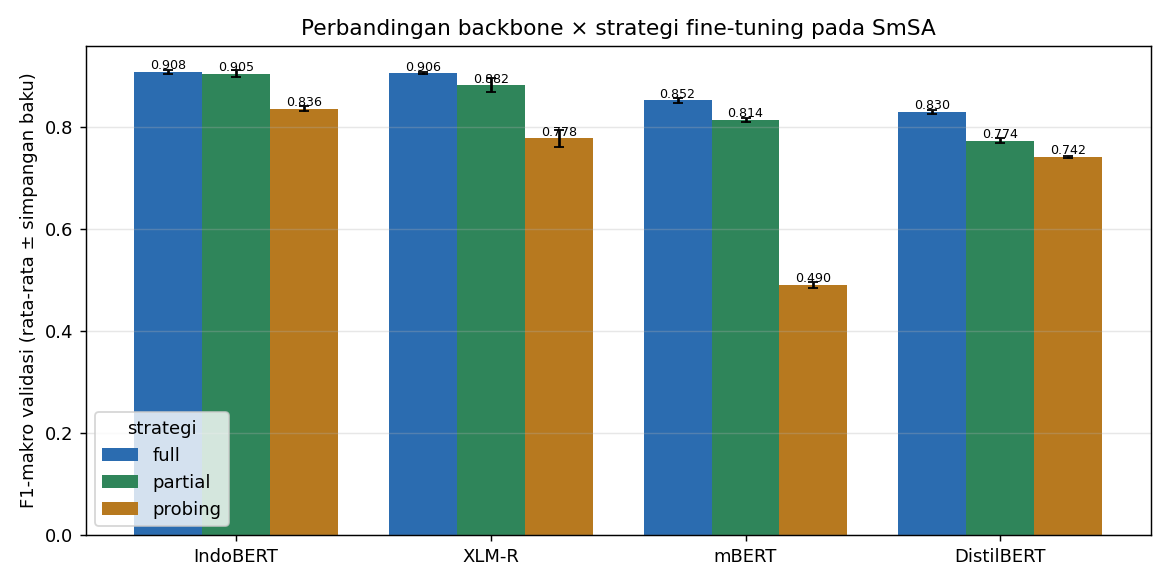

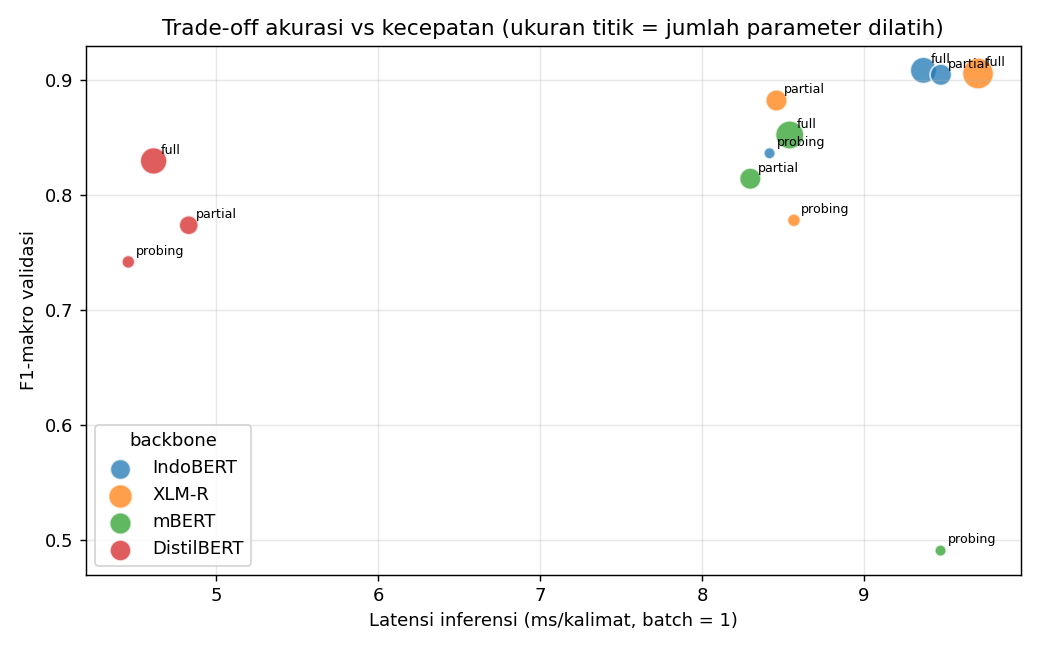

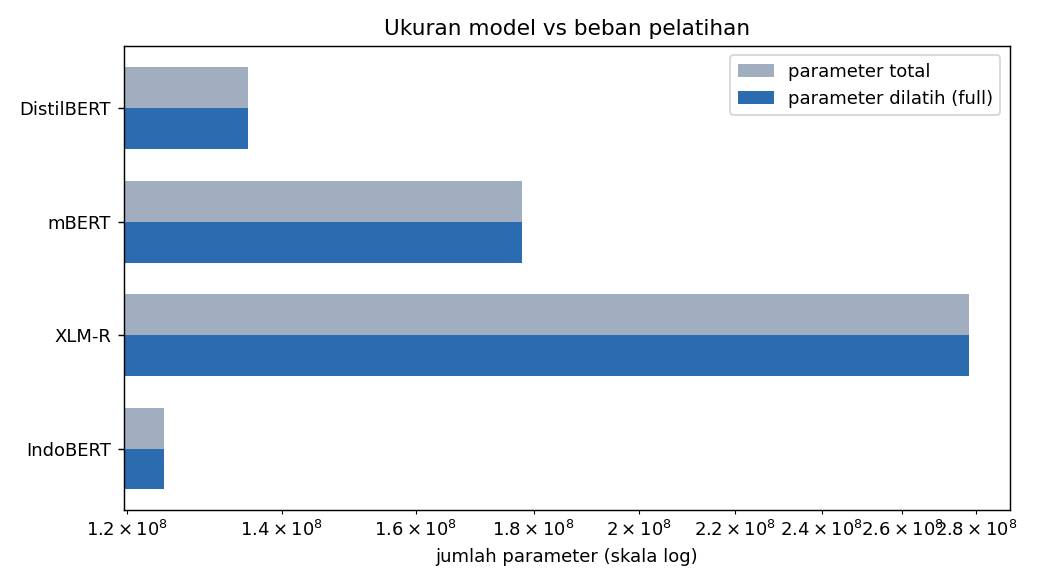

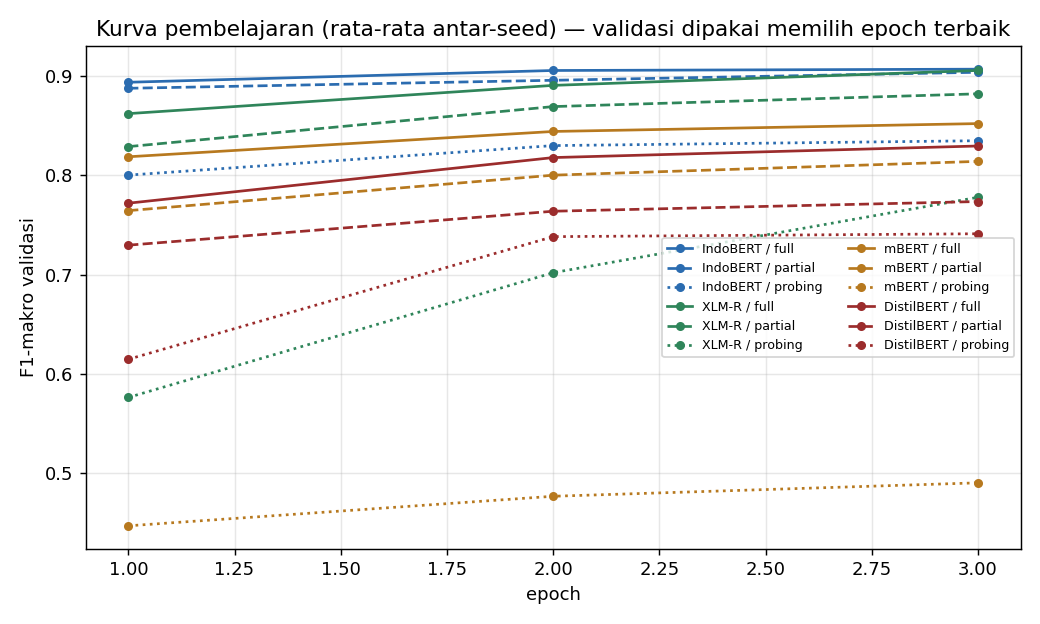

In [ ]:
# 11. GRAFIK UNTUK LAPORAN DAN SLIDE

def tampilkan(path):
    try:
        from IPython.display import display, Image
        display(Image(filename=path))
    except Exception:
        print(f"grafik tersimpan: {path}")


def buat_grafik(df, agg):
    bb_list = list(dict.fromkeys(agg["backbone"]))
    st_list = [s for s in STRATEGIES if s in set(agg["strategi"])]
    warna = {"full": "#2b6cb0", "partial": "#2f855a", "probing": "#b7791f"}

    # (a) F1-makro per backbone x strategi
    fig, ax = plt.subplots(figsize=(9, 4.5), dpi=130)
    x = np.arange(len(bb_list))
    lebar = 0.8 / max(1, len(st_list))
    for j, st in enumerate(st_list):
        nilai, err = [], []
        for bb in bb_list:
            b = agg[(agg.backbone == bb) & (agg.strategi == st)]
            nilai.append(float(b["val_f1_macro_mean"].iloc[0]) if len(b) else np.nan)
            err.append(float(b["val_f1_macro_std"].iloc[0]) if len(b) else 0.0)
        pos = x + (j - (len(st_list) - 1) / 2) * lebar
        ax.bar(pos, nilai, lebar, yerr=err, capsize=3, label=st, color=warna.get(st, None))
        for xi, v in zip(pos, nilai):
            if v == v:
                ax.text(xi, v + 0.005, f"{v:.3f}", ha="center", fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels(bb_list)
    ax.set_ylabel("F1-makro validasi (rata-rata ± simpangan baku)")
    ax.set_title("Perbandingan backbone × strategi fine-tuning pada SmSA")
    ax.grid(axis="y", alpha=0.3)
    ax.legend(title="strategi")
    fig.tight_layout()
    p1 = f"grafik_f1_{KODE}.png"
    fig.savefig(p1)
    plt.close(fig)

    # (b) latensi vs F1
    fig, ax = plt.subplots(figsize=(8, 5), dpi=130)
    for bb in bb_list:
        b = agg[agg.backbone == bb]
        ukuran = 40 + 260 * (b["param_dilatih"] / agg["param_dilatih"].max()) ** 0.5
        ax.scatter(b["latensi_ms_per_kalimat_mean"], b["val_f1_macro_mean"], s=ukuran,
                   alpha=0.75, label=bb, edgecolor="white")
        for _, r in b.iterrows():
            ax.annotate(r["strategi"], (r["latensi_ms_per_kalimat_mean"], r["val_f1_macro_mean"]),
                        fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("Latensi inferensi (ms/kalimat, batch = 1)")
    ax.set_ylabel("F1-makro validasi")
    ax.set_title("Trade-off akurasi vs kecepatan (ukuran titik = jumlah parameter dilatih)")
    ax.grid(alpha=0.3)
    ax.legend(title="backbone")
    fig.tight_layout()
    p2 = f"grafik_latensi_{KODE}.png"
    fig.savefig(p2)
    plt.close(fig)

    # (c) parameter total vs parameter dilatih
    fig, ax = plt.subplots(figsize=(8, 4.5), dpi=130)
    y = np.arange(len(bb_list))
    total = [float(agg[agg.backbone == bb]["total_param"].iloc[0]) for bb in bb_list]
    latih = [float(agg[agg.backbone == bb]["param_dilatih"].max()) for bb in bb_list]
    ax.barh(y + 0.18, total, 0.36, label="parameter total", color="#a0aec0")
    ax.barh(y - 0.18, latih, 0.36, label="parameter dilatih (full)", color="#2b6cb0")
    ax.set_xscale("log")
    ax.set_yticks(y)
    ax.set_yticklabels(bb_list)
    ax.set_xlabel("jumlah parameter (skala log)")
    ax.set_title("Ukuran model vs beban pelatihan")
    ax.grid(axis="x", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    p3 = f"grafik_param_{KODE}.png"
    fig.savefig(p3)
    plt.close(fig)

    # (d) kurva pembelajaran: F1-makro validasi tiap epoch (rata-rata antar-seed)
    fig, ax = plt.subplots(figsize=(8, 4.8), dpi=130)
    palet = ["#2b6cb0", "#2f855a", "#b7791f", "#9b2c2c"]
    gaya = {"full": "-", "partial": "--", "probing": ":"}
    warna_bb = {bb: palet[i % len(palet)] for i, bb in enumerate(bb_list)}
    _pakai = df[df["epochs"] == EPOCHS]
    for bb in bb_list:
        for st in st_list:
            sub = _pakai[(_pakai.backbone == bb) & (_pakai.strategi == st)]
            kurva = []
            for nilai in sub["kurva_val_f1"].astype(str):
                if ";" not in nilai and nilai.replace(".", "").isdigit() is False:
                    continue
                try:
                    kurva.append([float(x) for x in nilai.split(";")])
                except ValueError:
                    continue
            if not kurva:
                continue
            arr = np.array(kurva)
            ax.plot(range(1, arr.shape[1] + 1), arr.mean(axis=0), marker="o", markersize=4,
                    color=warna_bb[bb], linestyle=gaya.get(st, "-"), label=f"{bb} / {st}")
    ax.set_xlabel("epoch")
    ax.set_ylabel("F1-makro validasi")
    ax.set_title("Kurva pembelajaran (rata-rata antar-seed) — validasi dipakai memilih epoch terbaik")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, ncol=2)
    fig.tight_layout()
    p4 = f"grafik_kurva_{KODE}.png"
    fig.savefig(p4)
    plt.close(fig)
    return [p1, p2, p3, p4]


if AGREGAT is not None and len(AGREGAT):
    for _p in buat_grafik(HASIL, AGREGAT):
        tampilkan(_p)
else:
    print("Belum ada hasil untuk digambar.")

## 12b. Bahan jawaban 3 Pertanyaan Riset Wajib

Sel di bawah menyiapkan bahan jawaban dari CSV hasil sesuai tuntutan lembar studi kasus. Angka dari sini dipakai di slide dan laporan.

Q1 menanyakan backbone mana yang punya trade-off akurasi dan efisiensi terbaik. Jawabannya harus menyebut F1-makro ± SD, waktu latih, waktu inferensi, dan jumlah parameter.
Q2 menanyakan apakah strategi hemat komputasi (probing atau partial) cukup kompetitif dibanding full fine-tuning. Selisihnya dibandingkan dengan simpangan antar-seed.
Q3 menanyakan kombinasi apa yang direkomendasikan dan alasannya. Kriteria ditetapkan lebih dulu.

Catatan membaca output: peringatan 19 run di bawah baseline TF-IDF pada output di bawah membandingkan F1 validasi dengan baseline validasi (0,8371). Pembanding yang kami pakai untuk kesimpulan adalah F1 uji, dengan baseline TF-IDF terbaik 0,6408. Pada data uji hanya tiga konfigurasi yang rata-ratanya di bawah baseline yaitu DistilBERT partial, DistilBERT probing, dan mBERT probing. Rinciannya ada di bagian Catatan keterbatasan pada sel 14.


In [ ]:
# 12b. BAHAN JAWABAN Q1, Q2, Q3 + PERBANDINGAN DENGAN BASELINE TF-IDF

def skor_tradeoff(agg):
    """Skor gabungan ternormalisasi 0-1. Bobot adalah PILIHAN kami, bukan angka dari lembar studi kasus."""
    t = agg.copy()

    def normal(s, terbalik=False):
        a, b = float(s.min()), float(s.max())
        if b == a:
            return pd.Series([1.0] * len(s), index=s.index)
        v = (s - a) / (b - a)
        return (1 - v) if terbalik else v

    t["skor_f1"] = normal(t["val_f1_macro_mean"]).round(3)
    t["skor_latensi"] = normal(t["latensi_ms_per_kalimat_mean"], terbalik=True).round(3)
    t["skor_waktu"] = normal(t["waktu_latih_s_mean"], terbalik=True).round(3)
    t["skor_param"] = normal(t["param_dilatih"], terbalik=True).round(3)
    t["skor_gabungan"] = (0.6 * t["skor_f1"] + 0.2 * t["skor_latensi"]
                          + 0.1 * t["skor_waktu"] + 0.1 * t["skor_param"]).round(4)
    return t.sort_values("skor_gabungan", ascending=False)


if AGREGAT is None or not len(AGREGAT):
    raise RuntimeError("Belum ada hasil. Jalankan dulu sel loop eksperimen (bagian 9b).")

print("=" * 78)
print("Q1 — TRADE-OFF AKURASI vs EFISIENSI (semua angka rata-rata ± simpangan baku antar-seed)")
print("=" * 78)
_q1 = AGREGAT[["backbone", "strategi", "jumlah_seed", "val_f1_macro_mean", "val_f1_macro_std",
               "test_f1_macro_mean", "waktu_latih_s_mean", "latensi_ms_per_kalimat_mean",
               "param_dilatih", "total_param"]].copy()
_q1["F1_makro_val"] = _q1["val_f1_macro_mean"].map("{:.4f}".format) + " ± " + _q1["val_f1_macro_std"].map("{:.4f}".format)
print(_q1[["backbone", "strategi", "jumlah_seed", "F1_makro_val", "test_f1_macro_mean",
           "waktu_latih_s_mean", "latensi_ms_per_kalimat_mean", "param_dilatih", "total_param"]].to_string(index=False))

print("\nPeringkat per backbone pada strategi full (dipakai menjawab 'backbone mana yang terbaik'):")
_full = AGREGAT[AGREGAT.strategi == "full"].sort_values("val_f1_macro_mean", ascending=False)
print(_full[["backbone", "val_f1_macro_mean", "val_f1_macro_std", "test_f1_macro_mean",
             "waktu_latih_s_mean", "latensi_ms_per_kalimat_mean", "total_param"]].to_string(index=False))

_skor = skor_tradeoff(AGREGAT)
print("\nSkor gabungan ternormalisasi (0,6·F1 + 0,2·latensi + 0,1·waktu latih + 0,1·jumlah parameter):")
print(_skor[["backbone", "strategi", "skor_f1", "skor_latensi", "skor_waktu", "skor_param",
             "skor_gabungan"]].head(8).to_string(index=False))

_baseline_terbaik = float(BASELINE["val_f1_macro"].max()) if (BASELINE is not None and len(BASELINE)) else None
_f1_max = float(AGREGAT["val_f1_macro_mean"].max())
_sd_max = float(AGREGAT["val_f1_macro_std"].max())

print("\nDua kriteria pemilihan yang kami tetapkan lebih dulu:")
_kandidat_a = AGREGAT[AGREGAT["val_f1_macro_mean"] >= _f1_max - _sd_max]
if len(_kandidat_a):
    _pilih_a = _kandidat_a.sort_values("latensi_ms_per_kalimat_mean").iloc[0]
    print(f"  Kriteria A (akurasi dulu): semua sel dengan F1 >= {_f1_max - _sd_max:.4f} (F1 tertinggi - simpangan terbesar)")
    print(f"     -> dipilih {_pilih_a['backbone']} | {_pilih_a['strategi']} "
          f"(F1 {_pilih_a['val_f1_macro_mean']:.4f} ± {_pilih_a['val_f1_macro_std']:.4f}, "
          f"{_pilih_a['latensi_ms_per_kalimat_mean']:.1f} ms/kalimat, {int(_pilih_a['param_dilatih']):,} parameter dilatih)")
if _baseline_terbaik is not None:
    _kandidat_b = AGREGAT[AGREGAT["val_f1_macro_mean"] >= _baseline_terbaik + 0.02]
    if len(_kandidat_b):
        _pilih_b = _kandidat_b.sort_values("latensi_ms_per_kalimat_mean").iloc[0]
        print(f"  Kriteria B (efisiensi dulu): semua sel dengan F1 >= baseline TF-IDF + 0,02 ({_baseline_terbaik + 0.02:.4f})")
        print(f"     -> dipilih {_pilih_b['backbone']} | {_pilih_b['strategi']} "
              f"(F1 {_pilih_b['val_f1_macro_mean']:.4f} ± {_pilih_b['val_f1_macro_std']:.4f}, "
              f"{_pilih_b['latensi_ms_per_kalimat_mean']:.1f} ms/kalimat, {int(_pilih_b['param_dilatih']):,} parameter dilatih)")
    else:
        print("  Kriteria B: tidak ada sel yang melampaui baseline TF-IDF + 0,02.")

print("\n" + "=" * 78)
print("Q2 — APAKAH PROBING / PARTIAL CUKUP KOMPETITIF? (selisih dibandingkan simpangan antar-seed)")
print("=" * 78)
print("Aturan keputusan: selisih F1 dinyatakan BERMAKNA bila |selisih| > simpangan gabungan antar-seed,")
print("dengan simpangan gabungan = akar((SD_full^2 + SD_pembanding^2) / 2). Dengan 3 seed, ini heuristik")
print("sederhana - bukan uji statistik formal - dan akan kami sebutkan apa adanya di laporan.")
_Q2 = []
for _bb in [b for b in dict.fromkeys(AGREGAT["backbone"])]:
    _b = {st: AGREGAT[(AGREGAT.backbone == _bb) & (AGREGAT.strategi == st)] for st in ("full", "partial", "probing")}
    if not len(_b["full"]):
        continue
    _f1f = float(_b["full"].iloc[0]["val_f1_macro_mean"])
    _sdf = float(_b["full"].iloc[0]["val_f1_macro_std"])
    for _st in ("partial", "probing"):
        if not len(_b[_st]):
            continue
        _f1s = float(_b[_st].iloc[0]["val_f1_macro_mean"])
        _sds = float(_b[_st].iloc[0]["val_f1_macro_std"])
        _selisih = _f1f - _f1s
        _gab = math.sqrt((_sdf ** 2 + _sds ** 2) / 2)
        _Q2.append({"backbone": _bb, "pembanding": _st, "F1_full": round(_f1f, 4), "F1_pembanding": round(_f1s, 4),
                    "selisih": round(_selisih, 4), "simpangan_gabungan": round(_gab, 4),
                    "putusan": "BERBEDA bermakna" if abs(_selisih) > _gab else "BELUM berbeda (selisih < simpangan)",
                    "hemat": f"{100 * (1 - float(_b[_st].iloc[0]['param_dilatih']) / float(_b['full'].iloc[0]['param_dilatih'])):.2f}% parameter"})
print(pd.DataFrame(_Q2).to_string(index=False))

print("\n" + "=" * 78)
print("Q3 — PERBANDINGAN DENGAN PEMBANDING YANG SAH")
print("=" * 78)
if BASELINE is not None and len(BASELINE):
    print(BASELINE[["baseline", "n_train", "val_accuracy", "val_f1_macro", "test_f1_macro",
                    "waktu_latih_s", "latensi_ms_per_kalimat"]].to_string(index=False))
    _terbaik = HASIL.sort_values("val_f1_macro", ascending=False).iloc[0]
    print(f"\nModel neural terbaik: {_terbaik['backbone']} | {_terbaik['strategi']} | seed {_terbaik['seed']} "
          f"-> val F1-makro {_terbaik['val_f1_macro']:.4f}")
    print(f"Selisih terhadap baseline TF-IDF terbaik: {_terbaik['val_f1_macro'] - _baseline_terbaik:+.4f}")
    print(f"Tebakan acak untuk acuan: {1 / len(LABELS):.4f}")
    _di_bawah = HASIL[HASIL["val_f1_macro"] < _baseline_terbaik]
    if len(_di_bawah):
        print(f"\nPERINGATAN: {len(_di_bawah)} run berada DI BAWAH baseline TF-IDF -> "
              "periksa learning rate, pemetaan label, dan apakah model benar-benar terlatih:")
        print(_di_bawah[["backbone", "strategi", "seed", "val_f1_macro", "lr", "epochs"]].to_string(index=False))
    _mencurigakan = HASIL[HASIL["test_f1_macro"] > 0.97]
    if len(_mencurigakan):
        print(f"\nPERINGATAN: {len(_mencurigakan)} run punya F1-makro test > 0,97. Lembar studi kasus menyebut skor "
              "setinggi itu patut dicurigai kebocoran data -> periksa ulang split dan pembersihan duplikat.")
    else:
        print("\nTidak ada run dengan F1-makro test > 0,97 (tidak ada tanda kebocoran data).")
    print("\nUntuk Q3, susun rekomendasi dengan urutan: kriteria -> bukti angka -> konsekuensi biaya. "
          "Pakai tabel skor gabungan dan kedua kriteria di atas sebagai dasarnya.")
else:
    print("Baseline TF-IDF tidak tersedia (BASELINE_TFIDF = False), jadi perbandingan ini dilewati.")

print("\n" + "=" * 78)
print("PEMERIKSAAN KEWAJARAN (lembar studi kasus)")
print("=" * 78)
_cek = []
for _bb in dict.fromkeys(AGREGAT["backbone"]):
    _b = AGREGAT[AGREGAT.backbone == _bb]
    _full = _b[_b.strategi == "full"]
    _prob = _b[_b.strategi == "probing"]
    if len(_full) and len(_prob):
        _cek.append({"backbone": _bb,
                     "full >= probing?": bool(float(_full.iloc[0]["val_f1_macro_mean"]) >= float(_prob.iloc[0]["val_f1_macro_mean"])),
                     "selisih": round(float(_full.iloc[0]["val_f1_macro_mean"]) - float(_prob.iloc[0]["val_f1_macro_mean"]), 4)})
print(pd.DataFrame(_cek).to_string(index=False))
print("Kalau ada backbone dengan full < probing, periksa dulu kemungkinan bug sebelum melaporkannya sebagai temuan.")

Q1 — TRADE-OFF AKURASI vs EFISIENSI (semua angka rata-rata ± simpangan baku antar-seed)
  backbone strategi  jumlah_seed    F1_makro_val  test_f1_macro_mean  waktu_latih_s_mean  latensi_ms_per_kalimat_mean  param_dilatih  total_param
  IndoBERT     full            3 0.9085 ± 0.0044            0.862433          300.013333                     9.366667      124443651    124443651
     XLM-R     full            3 0.9057 ± 0.0020            0.872700          396.656667                     9.703667      278045955    278045955
  IndoBERT  partial            3 0.9046 ± 0.0070            0.869267          206.280000                     9.474333       43120131    124443651
     XLM-R  partial            3 0.8822 ± 0.0139            0.850100          223.916667                     8.459000       43120131    278045955
     mBERT     full            3 0.8522 ± 0.0048            0.763333          371.803333                     8.540667      177855747    177855747
  IndoBERT  probing            3 0.8

## 12. Gabungkan hasil antar-anggota

Sel ini dijalankan setelah semua anggota selesai. Kumpulkan berkas hasil_smsa_<kode>_<anggota>.csv dari tiap anggota ke satu folder bersama notebook ini lalu jalankan sel di bawah. Notebook akan menggabungkannya, memeriksa kelengkapan matriks, dan menulis berkas akhir sesuai format spesifikasi.


In [ ]:
print("Berkas hasil yang ditemukan di folder ini:")
_berkas = sorted(glob.glob(f"hasil_{DATASET_NAME}_{KODE}*.csv"))
for _b in _berkas:
    try:
        _n = len(pd.read_csv(_b))
    except Exception:
        _n = "?"
    print(f"   {_b}  ({_n} run)")
if not _berkas:
    print("   (belum ada berkas hasil)")

HASIL, AGREGAT = tulis_output()

if HASIL is not None and len(HASIL):
    _kurang = []
    for _bb in BACKBONES:
        for _st in STRATEGIES:
            for _sd in SEEDS:
                _ada = HASIL[(HASIL.backbone == _bb) & (HASIL.strategi == _st) &
                             (HASIL.seed == _sd) & (~HASIL.bobot_kelas.astype(bool))]
                if not len(_ada):
                    _kurang.append((_bb, _st, _sd))
    print(f"\nTotal run terkumpul: {len(HASIL)} dari target "
          f"{len(BACKBONES) * len(STRATEGIES) * len(SEEDS)} run matriks utama (4 backbone x 3 strategi x 3 seed).")
    if _kurang:
        print(f"Sel yang belum terisi: {len(_kurang)}")
        for _k in _kurang[:15]:
            print("   ", _k)
        if len(_kurang) > 15:
            print(f"    ... dan {len(_kurang) - 15} sel lainnya")
        print("Berkas dari anggota yang belum menyerahkan hasil: minta mereka menjalankan gilirannya lebih dulu.")
    else:
        print("Matriks LENGKAP: setiap backbone x strategi sudah punya hasil di ketiga seed.")
    print("\nRingkasan agregat:")
    _kol = ["val_accuracy", "val_f1_macro", "test_f1_macro", "waktu_latih_s", "latensi_ms_per_kalimat"]
    _t = AGREGAT.copy()
    for _k in _kol:
        _t[_k] = _t[f"{_k}_mean"].map("{:.4f}".format) + " ± " + _t[f"{_k}_std"].map("{:.4f}".format)
    print(_t[["backbone", "strategi", "jumlah_seed", "val_f1_macro", "test_f1_macro",
              "waktu_latih_s", "latensi_ms_per_kalimat"]].to_string(index=False))

Berkas hasil yang ditemukan di folder ini:
   hasil_smsa_c7e6d734.csv  (36 run)
   hasil_smsa_c7e6d734_anggota1.csv  (36 run)
  ditulis: hasil_smsa_c7e6d734.csv (36 run) dan rekap_agregat_smsa_c7e6d734.csv (12 sel)

Total run terkumpul: 36 dari target 36 run matriks utama (4 backbone x 3 strategi x 3 seed).
Matriks LENGKAP: setiap backbone x strategi sudah punya hasil di ketiga seed.

Ringkasan agregat:
  backbone strategi  jumlah_seed    val_f1_macro   test_f1_macro      waktu_latih_s latensi_ms_per_kalimat
  IndoBERT     full            3 0.9085 ± 0.0044 0.8624 ± 0.0071  300.0133 ± 0.2901        9.3667 ± 1.8337
     XLM-R     full            3 0.9057 ± 0.0020 0.8727 ± 0.0104  396.6567 ± 0.3953        9.7037 ± 0.6779
  IndoBERT  partial            3 0.9046 ± 0.0070 0.8693 ± 0.0232 206.2800 ± 12.2805        9.4743 ± 0.7739
     XLM-R  partial            3 0.8822 ± 0.0139 0.8501 ± 0.0093  223.9167 ± 0.3602        8.4590 ± 0.0693
     mBERT     full            3 0.8522 ± 0.0048 0.7633 ± 

## 13. Analisis kesalahan dan ablasi (opsional)

Sel di bawah bersifat opsional dan tidak masuk matriks utama. Tujuannya memperdalam bagian analisis laporan.

- Ablasi A memakai loss berbobot kelas. Data latih tidak seimbang karena kelas neutral hanya sekitar 10,4 persen. Ablasi ini mengukur seberapa besar F1-makro bisa naik kalau kelas minoritas diberi bobot lebih besar.
- Ablasi B menjalankan probing dengan 15 epoch. Ablasi ini mengukur seberapa banyak selisih probing dan full yang sebenarnya hanya soal jumlah langkah latih dan bukan keterbatasan representasi.
- Analisis kesalahan melatih ulang konfigurasi terbaik di validasi dengan seed yang sama. Hasilnya berupa confusion matrix dan contoh kalimat yang salah diklasifikasi. Bagian ini berguna untuk slide keterjelasan.


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Melatih ulang konfigurasi terbaik (IndoBERT | full | seed=42) untuk analisis kesalahan...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


IndoBERT|full|s42 ep1/3:   0%|          | 0/188 [00:00<?, ?it/s]

   epoch 1/3: val loss=0.2023 val akurasi=0.9270 val F1-makro=0.8935


IndoBERT|full|s42 ep2/3:   0%|          | 0/188 [00:00<?, ?it/s]

   epoch 2/3: val loss=0.2281 val akurasi=0.9350 val F1-makro=0.9128


IndoBERT|full|s42 ep3/3:   0%|          | 0/188 [00:00<?, ?it/s]

   epoch 3/3: val loss=0.2414 val akurasi=0.9334 val F1-makro=0.9085

Pemeriksaan kewajaran: F1-makro validasi hasil pelatihan ulang = 0.9128 (tercatat di tabel: 0.9128). Angka yang identik menandakan hasil bisa direproduksi.

Laporan klasifikasi (data validasi):
              precision    recall  f1-score   support

    positive     0.9611    0.9492    0.9551       728
     neutral     0.9286    0.8062    0.8631       129
    negative     0.8916    0.9512    0.9204       389

    accuracy                         0.9350      1246
   macro avg     0.9271    0.9022    0.9128      1246
weighted avg     0.9360    0.9350    0.9347      1246

Confusion matrix (baris = label asli, kolom = prediksi):
               pred_positive  pred_neutral  pred_negative
asli_positive            691             6             31
asli_neutral              11           104             14
asli_negative             17             2            370

81 dari 1246 contoh validasi salah diprediksi. Contoh:
  asli=pos

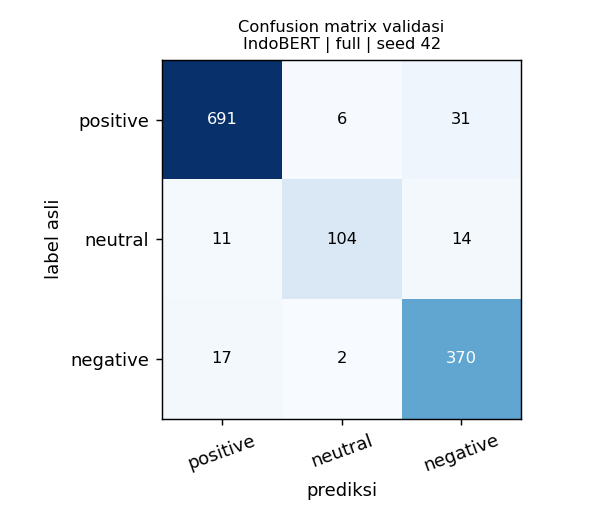

In [ ]:
JALANKAN_ABLASI = False
JALANKAN_ANALISIS_ERROR = True

if JALANKAN_ABLASI:
    if AGREGAT is None or not len(AGREGAT):
        print("Belum ada tabel agregat. Jalankan dulu sel loop eksperimen dan sel agregat.")
    else:
        _bb_pilih = AGREGAT.iloc[0]["backbone"]
        _st_pilih = AGREGAT.iloc[0]["strategi"]
        print(f"Konfigurasi terbaik menurut split validasi: {_bb_pilih} | {_st_pilih}")

        _hitung = pd.Series(LBL["train"]).value_counts().reindex(range(len(LABELS))).fillna(1.0)
        _bobot = (len(LBL["train"]) / (len(LABELS) * _hitung)).tolist()
        print(f"Bobot kelas untuk loss (positive, neutral, negative) = {[round(w, 3) for w in _bobot]}")
        simpan_baris(jalankan_run(_bb_pilih, _st_pilih, int(SEEDS[0]), bobot_kelas=_bobot,
                                  catatan="ablasi A: class-weighted CE"))

        _bb_probing = "IndoBERT" if "IndoBERT" in BACKBONES else _bb_pilih
        simpan_baris(jalankan_run(_bb_probing, "probing", int(SEEDS[0]), epochs=15,
                                  catatan="ablasi B: probing 15 epoch"))

        HASIL, AGREGAT = tulis_output()
        _ab = HASIL[HASIL["catatan"].fillna("").astype(str) != ""]
        print("\nPerbandingan ablasi dengan run matriks utama (perhatikan val_f1_macro dan val_f1_neutral):")
        print(_ab[["backbone", "strategi", "seed", "epochs", "bobot_kelas", "catatan",
                   "val_f1_macro", "val_f1_neutral"]].to_string(index=False))

if JALANKAN_ANALISIS_ERROR:
    if HASIL is None or not len(HASIL):
        print("Belum ada hasil. Jalankan dulu sel loop eksperimen.")
    else:
        _peringkat = HASIL.groupby(["backbone", "strategi"])["val_f1_macro"].mean().sort_values(ascending=False)
        _bb_best, _st_best = _peringkat.index[0]
        _sub = HASIL[(HASIL.backbone == _bb_best) & (HASIL.strategi == _st_best)]
        _seed_best = int(_sub.sort_values("val_f1_macro", ascending=False).iloc[0]["seed"])
        print(f"Melatih ulang konfigurasi terbaik ({_bb_best} | {_st_best} | seed={_seed_best}) "
              "untuk analisis kesalahan...")
        _baris_baik, model_baik = jalankan_run(_bb_best, _st_best, _seed_best, catat_ke_csv=False)
        _loader_valid = buat_loader(_bb_best, "valid", EVAL_BATCH)
        _hasil_best = evaluasi(model_baik, _loader_valid)

        print(f"\nPemeriksaan kewajaran: F1-makro validasi hasil pelatihan ulang = {_hasil_best['f1_macro']:.4f} "
              f"(tercatat di tabel: {_baris_baik['val_f1_macro']:.4f}). "
              "Angka yang identik menandakan hasil bisa direproduksi.")
        print("\nLaporan klasifikasi (data validasi):")
        print(classification_report(_hasil_best["y_true"], _hasil_best["prediksi"], target_names=LABELS, digits=4))

        _cm = confusion_matrix(_hasil_best["y_true"], _hasil_best["prediksi"], labels=list(range(len(LABELS))))
        print("Confusion matrix (baris = label asli, kolom = prediksi):")
        print(pd.DataFrame(_cm, index=[f"asli_{l}" for l in LABELS],
                           columns=[f"pred_{l}" for l in LABELS]).to_string())

        _salah = np.where(_hasil_best["prediksi"] != _hasil_best["y_true"])[0]
        print(f"\n{len(_salah)} dari {len(_hasil_best['y_true'])} contoh validasi salah diprediksi. Contoh:")
        for _i in _salah[:8]:
            print(f"  asli={LABELS[_hasil_best['y_true'][_i]]:8s} -> prediksi="
                  f"{LABELS[_hasil_best['prediksi'][_i]]:8s} | {TXT['valid'][_i][:140]}")

        _fig, _ax = plt.subplots(figsize=(4.6, 4), dpi=130)
        _im = _ax.imshow(_cm, cmap="Blues")
        for _r in range(len(LABELS)):
            for _c in range(len(LABELS)):
                _ax.text(_c, _r, _cm[_r, _c], ha="center", va="center", fontsize=9,
                         color="white" if _cm[_r, _c] > _cm.max() / 2 else "black")
        _ax.set_xticks(range(len(LABELS)))
        _ax.set_xticklabels(LABELS, rotation=20)
        _ax.set_yticks(range(len(LABELS)))
        _ax.set_yticklabels(LABELS)
        _ax.set_xlabel("prediksi")
        _ax.set_ylabel("label asli")
        _ax.set_title(f"Confusion matrix validasi\n{_bb_best} | {_st_best} | seed {_seed_best}", fontsize=9)
        _fig.tight_layout()
        _path_cm = f"grafik_confusion_{KODE}.png"
        _fig.savefig(_path_cm)
        plt.close(_fig)

        del model_baik
        gc.collect()
        if GPU:
            torch.cuda.empty_cache()
        tampilkan(_path_cm)

## 13b. Benchmark latensi dalam satu sesi

Spesifikasi menyatakan latensi hanya boleh dibandingkan dalam sesi yang sama. Sel di bawah mengukur latensi (ms per kalimat dengan batch 1) untuk semua backbone di satu mesin. Modelnya tidak dilatih karena latensi bergantung pada arsitektur dan bukan pada bobot. Sel ini dijalankan di satu sesi oleh satu orang. Angkanya dipakai untuk Q1 dan Q3 dan jenis GPU-nya disebut di laporan.


In [ ]:
# 13b. BENCHMARK LATENSI SATU SESI (semua backbone, mesin yang sama)

_hasil_lat = []
for _bb in BACKBONES:
    _m = AutoModelForSequenceClassification.from_pretrained(BACKBONES[_bb], num_labels=len(LABELS), ignore_mismatched_sizes=True).to(DEVICE)
    _lat = [ukur_latensi(_m, _bb) for _ in range(3)]       # 3 pengulangan -> rata-rata dan simpangan
    _hasil_lat.append({"backbone": _bb, "latensi_ms_mean": round(float(np.mean(_lat)), 3),
                       "latensi_ms_std": round(float(np.std(_lat, ddof=1)), 3),
                       "total_param": sum(p.numel() for p in _m.parameters()),
                       "perangkat": (torch.cuda.get_device_name(0) if GPU else "CPU")})
    del _m; gc.collect()
    if GPU: torch.cuda.empty_cache()
LATENSI_SESI = pd.DataFrame(_hasil_lat)
LATENSI_SESI.to_csv(f"latensi_satu_sesi_{KODE}.csv", index=False)
print(LATENSI_SESI.to_string(index=False))


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p1
Key               | Status  | 
------------------+---------+-
classifier.bias   | MISSING | 
classifier.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  backbone  latensi_ms_mean  latensi_ms_std  total_param perangkat
     mBERT            8.506           0.459    177855747  Tesla T4
DistilBERT            4.259           0.053    135326979  Tesla T4
  IndoBERT            9.028           1.709    124443651  Tesla T4
     XLM-R            8.376           0.163    278045955  Tesla T4


## 14. Kesimpulan

### Backbone mana yang paling seimbang antara akurasi dan efisiensi?

IndoBERT dengan full fine-tuning memberikan hasil terbaik di data validasi. F1-makronya 0,9085 ± 0,0044 dan di data uji 0,8624 ± 0,0071. Modelnya punya 124,4 juta parameter dengan waktu latih sekitar 300 detik untuk 3 epoch. Latensinya sekitar 9,4 ms per kalimat.

XLM-R hasilnya hampir sama baiknya. F1-makro validasinya 0,9057 ± 0,0020 dan ujinya 0,8727 ± 0,0104. Selisihnya dengan IndoBERT masih berada dalam simpangan antar-seed sehingga kami tidak menyimpulkan bahwa XLM-R lebih unggul. Biayanya justru jauh lebih besar. Waktu latihnya 397 detik dan parameternya 278 juta atau lebih dari dua kali lipat IndoBERT.

mBERT tertinggal cukup jauh dengan F1-makro validasi 0,8522 ± 0,0048 dan uji 0,7633 ± 0,0349. Padahal ukurannya lebih besar dari IndoBERT dan waktu latihnya 372 detik. DistilBERT paling cepat dengan latensi sekitar 4,3 ms dan waktu latih 197 detik. Namun F1-makronya turun menjadi 0,8296 ± 0,0041 di validasi dan 0,7104 ± 0,0290 di uji.

Pada Tesla T4 latensi mBERT, IndoBERT, dan XLM-R hanya berkisar 8,4 sampai 9,0 ms. Selisih sekecil itu tidak bermakna sehingga hanya DistilBERT yang terbukti lebih cepat.

### Apakah strategi hemat komputasi cukup kompetitif?

Partial freezing bisa menjadi alternatif yang layak tetapi hasilnya tergantung backbone. Linear probing tidak cukup kompetitif.

Pada IndoBERT selisih F1-makro validasi antara full dan partial hanya 0,0039. Angka ini lebih kecil dari simpangan gabungan sebesar 0,0058. Di data uji partial bahkan sedikit lebih tinggi yaitu 0,8693 ± 0,0232 dibanding 0,8624 ± 0,0071. Padahal partial hanya melatih sekitar 35 persen parameter dan waktu latihnya lebih singkat yaitu 206 detik dibanding 300 detik.

Pada backbone lain partial kalah secara bermakna. Selisihnya 0,0235 pada XLM-R, 0,0381 pada mBERT, dan 0,0560 pada DistilBERT. Linear probing selalu di bawah full fine-tuning dengan selisih 0,0722 pada IndoBERT, 0,1278 pada XLM-R, 0,0879 pada DistilBERT, dan 0,3617 pada mBERT. Karena hanya memakai 3 seed perbandingan ini lebih tepat dipandang sebagai patokan kasar dan bukan uji statistik.

### Kombinasi yang direkomendasikan

Kami merekomendasikan IndoBERT dengan partial freezing.

Awalnya kami menetapkan dua kriteria pemilihan. Keduanya ternyata memilih berdasarkan latensi terendah. Kriteria A memilih IndoBERT full dan kriteria B memilih XLM-R partial. Padahal latensi tiga model 12 lapis hampir sama. Karena itu kami memakai kriteria akhir yang dirumuskan setelah melihat hasil. Pertama F1-makro harus termasuk yang tertinggi. Kedua biaya latih dan ukuran model sekecil mungkin. Ketiga latensi tidak lebih buruk dari kandidat lain.

Tiga konfigurasi memenuhi syarat akurasi yaitu IndoBERT full, XLM-R full, dan IndoBERT partial. Di antara ketiganya IndoBERT partial paling efisien. Waktu latihnya 206 detik dan parameter yang dilatih hanya 43,1 juta. Ukuran totalnya kurang dari separuh XLM-R. Latensinya tetap sekitar 9,5 ms sehingga penghematannya ada di biaya pelatihan dan bukan di kecepatan inferensi.

Rekomendasi ini bisa berubah sesuai kebutuhan.

- Jika kecepatan inferensi jadi prioritas, pilih DistilBERT full dengan latensi sekitar 4,3 ms. Konsekuensinya F1-makro turun sekitar 8 poin di validasi dan 15 poin di uji dibanding IndoBERT full.
- Jika anggaran komputasi longgar dan skor uji tertinggi jadi target, XLM-R full layak dipertimbangkan. Keunggulannya di data uji hanya sekitar 1 poin dan masih setara dengan simpangan antar-seed.

Skor gabungan di sel 12b memakai bobot 0,6 untuk F1, 0,2 untuk latensi, 0,1 untuk waktu latih, dan 0,1 untuk parameter. Dengan bobot itu DistilBERT full ada di peringkat pertama dan IndoBERT partial di peringkat kelima. Kami tidak memakainya secara langsung karena bobot latensinya terlalu besar untuk tiga backbone yang latensinya hampir sama.

Dari analisis kesalahan pada IndoBERT full seed 42 kelas neutral paling sulit dengan recall 0,806 dan F1 0,863. Kelas positive dan negative lebih baik dengan F1 masing-masing 0,955 dan 0,920. Analisis ini dilakukan pada IndoBERT full dan bukan partial sehingga hanya berfungsi sebagai gambaran umum.

### Status hipotesis

- H1 (IndoBERT > mBERT > DistilBERT) didukung. Pada full fine-tuning F1-makro validasinya 0,9085, 0,8522, dan 0,8296.
- H2 (full ≥ partial > probing) didukung sebagian. Urutannya sesuai di semua backbone. Namun partial hanya setara dengan full pada IndoBERT dan kalah bermakna pada tiga backbone lainnya.
- H3 ditolak. Kami memperkirakan XLM-R hanya unggul kurang dari 1 poin atas mBERT. Hasilnya XLM-R full unggul sekitar 5,4 poin F1-makro validasi. Keunggulan itu juga tidak muncul saat XLM-R dibandingkan dengan IndoBERT yang lebih kecil.

### Keterbatasan

- Probing pada mBERT hampir setara tebakan acak. F1-makro ujinya 0,345 ± 0,012 sedangkan tebakan acak 0,333. Padahal full dan partial pada mBERT berjalan normal dengan kode yang sama. Kami menduga representasi beku mBERT kurang memadai untuk probing pada learning rate 1e-3 dan 3 epoch. Dugaan ini belum diuji dengan learning rate lain seperti 5e-3.
- Baseline TF-IDF kuat di validasi tetapi turun jauh di uji. F1-makronya 0,8371 di validasi dan 0,6408 di uji. Peringatan 19 run di bawah baseline pada sel 12b membandingkan F1 validasi dengan baseline validasi sehingga terlalu ketat. Jika dibandingkan dengan F1 uji hanya tiga konfigurasi yang rata-ratanya di bawah baseline. Ketiganya adalah DistilBERT partial 0,6302, DistilBERT probing 0,5165, dan mBERT probing 0,3454.
- Skor validasi jauh lebih tinggi daripada skor uji pada hampir semua konfigurasi. Contohnya IndoBERT full 0,9085 di validasi dan 0,8624 di uji. Kami menduga sebaran kelas data uji berbeda termasuk porsi kelas neutral tetapi hal ini belum diperiksa lebih lanjut. Data uji juga hanya 500 kalimat sehingga simpangan antar-seed di uji lebih besar.
- Latensi diukur dengan batch 1 pada satu GPU sehingga lebih banyak dipengaruhi overhead GPU daripada ukuran model. Itu sebabnya model 12 lapis dengan ukuran berbeda punya latensi yang hampir sama.
- Probing pada DistilBERT dan XLM-R bukan linear murni karena head keduanya punya satu lapis dense 768 ke 768. Parameter yang dilatih 592.899 dan bukan 2.307 seperti pada BERT. Perbandingan probing antar-backbone perlu dibaca dengan catatan ini.
- Setiap konfigurasi hanya punya 3 seed sehingga simpangan baku yang dihitung kurang stabil.

Semua angka di atas adalah rata-rata dari 3 seed dengan simpangan baku antar-seed dari konfigurasi dengan kode `c7e6d734`.

In [1]:
!find / -name "hasil_smsa_*.csv" -o -name "rekap_agregat_smsa_*.csv" 2>/dev/null | grep -v proc

In [3]:
import os
print("Folder kerja:", os.getcwd())
!ls -la
!find / \( -name "hasil_smsa_*" -o -name "rekap_agregat_smsa_*" -o -name "baseline_tfidf_smsa_*" \) -not -path "/proc/*" 2>/dev/null

Folder kerja: /content
total 16
drwxr-xr-x 1 root root 4096 Nov 18 15:58 .
drwxr-xr-x 1 root root 4096 Nov 20 10:52 ..
drwxr-xr-x 4 root root 4096 Nov 18 15:58 .config
drwxr-xr-x 1 root root 4096 Nov 18 15:58 sample_data
